EDA (EXPLORATORY DATA ANALYSIS) OF SITES AND MONUMENTS



Feature engineering of the monuments dataset.


In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pandas as pd
import numpy as np
import seaborn as sns
import os
import json
import geoplot
import pysal
import re
from sklearn.feature_extraction.text import CountVectorizer
import sys
import contextily as ctx
sys.path.insert(0, '../ArchaeTron')
from FileManager import data_saver

# from src.ArchaeTron.GeoDataHandler import TextEntitySearch

In [2]:
# Import classes from the main program 

save_files = data_saver.DataSaver()


In [3]:
# Import the data

tuatha_nw_1600_mod = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/tuatha_nw_1600_mod.shp')

sites_nw_clean = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_clean.shp')
sites_nw_clean.columns


Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry'],
      dtype='object')

In [4]:
tuatha_nw_1600_mod.columns

Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'AIREACHT', 'FEDERATION',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'geometry'],
      dtype='object')

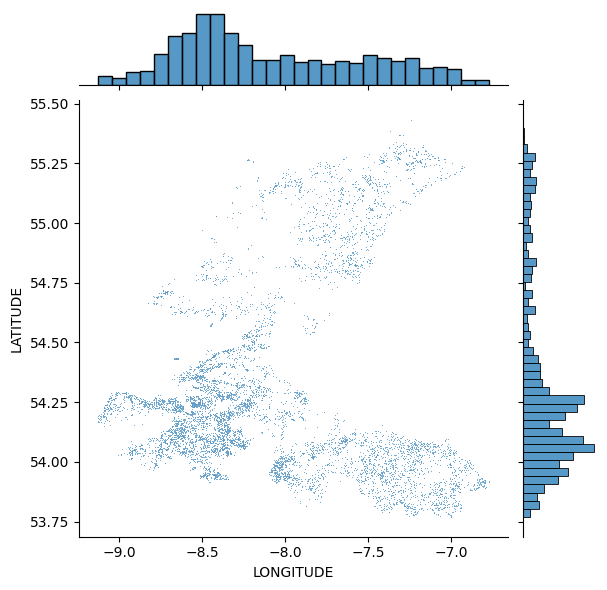

In [5]:
# Generate scatter plot, can see the overall distribution is towards the south of the area.

sns.jointplot(x="LONGITUDE", y="LATITUDE", data=sites_nw_clean, s=0.5);

CREATE A BUFFER FROM CENTRE OF EACH TERRITORY AND RETURN THE SITES WITHIN A CERTAIN DISTANCE


In [6]:
# Create a buffer from the centroid of each territory, this will be used to select sites within each territory
buffer_distance = 1800  # Set the buffer distance as needed

# Assign an ID to each territory
tuatha_nw_1600_mod['ID'] = range(len(tuatha_nw_1600_mod))

# Create a buffer from the centroid of each territory
buffer_df = gpd.GeoDataFrame({'geometry': tuatha_nw_1600_mod.centroid.buffer(buffer_distance), 'ID': tuatha_nw_1600_mod['ID']})

# Use a spatial join to match the monuments with the territories
monuments_in_buffer = gpd.sjoin(sites_nw_clean, buffer_df, how='inner', op='within')

# Count the number of unique MONUMENT_T in each buffer
unique_monuments = monuments_in_buffer.groupby('ID')['MONUMENT_T'].unique()
print(unique_monuments)


ID
2     [Ringfort - rath, Standing stone, Bawn, Barrow...
3     [Ringfort - rath, Standing stone, Cairn - uncl...
4            [Ritual site - holy well, Ringfort - rath]
5                                      [Standing stone]
6         [Ringfort - rath, Standing stone, Souterrain]
7     [Megalithic tomb - passage tomb, Ringfort - ra...
8     [Ringfort - rath, Mound, Barrow - unclassified...
9     [Megalithic tomb - portal tomb, Cairn - unclas...
10                             [Ringfort - rath, Mound]
11             [Cairn - boundary cairn, Boundary stone]
12    [Ringfort - rath, Souterrain, Barrow - bowl-ba...
13    [Ritual site - holy well, Ringfort - unclassif...
14    [Ringfort - rath, Souterrain, Ecclesiastical e...
15    [Bawn, Church, Ringfort - rath, Megalithic tom...
16                            [Ringfort - rath, Church]
18    [Ringfort - rath, Megalithic tomb - unclassifi...
19                        [Ringfort - rath, Souterrain]
20    [Ringfort - rath, Ritual site - holy we

/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3466: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


In [7]:
# Output the results to a text file
unique_monuments.to_csv('unique_monuments_buffer.txt', header=True)

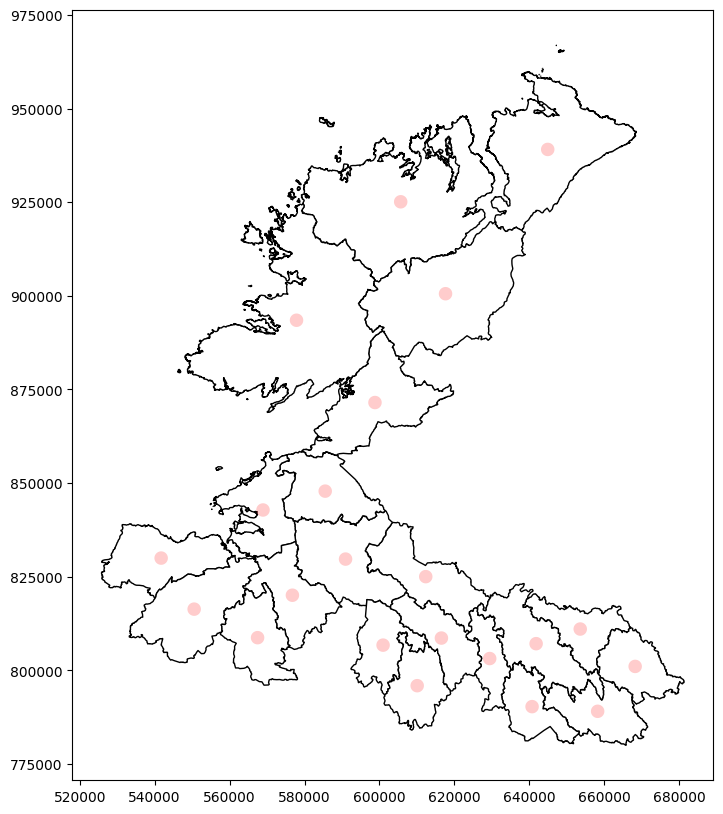

ValueError: Grouper and axis must be same length

In [8]:
#import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

# Plot the territories
tuatha_nw_1600_mod.plot(ax=ax, color='white', edgecolor='black')

# Plot the buffers as transparent circles
buffer_df.plot(ax=ax, color='red', alpha=0.2)

plt.show()

# Count the number of unique MONUMENT_T in each buffer
unique_monuments = monuments_in_buffer.groupby(buffer_df.index)['MONUMENT_T'].nunique()
print(unique_monuments)

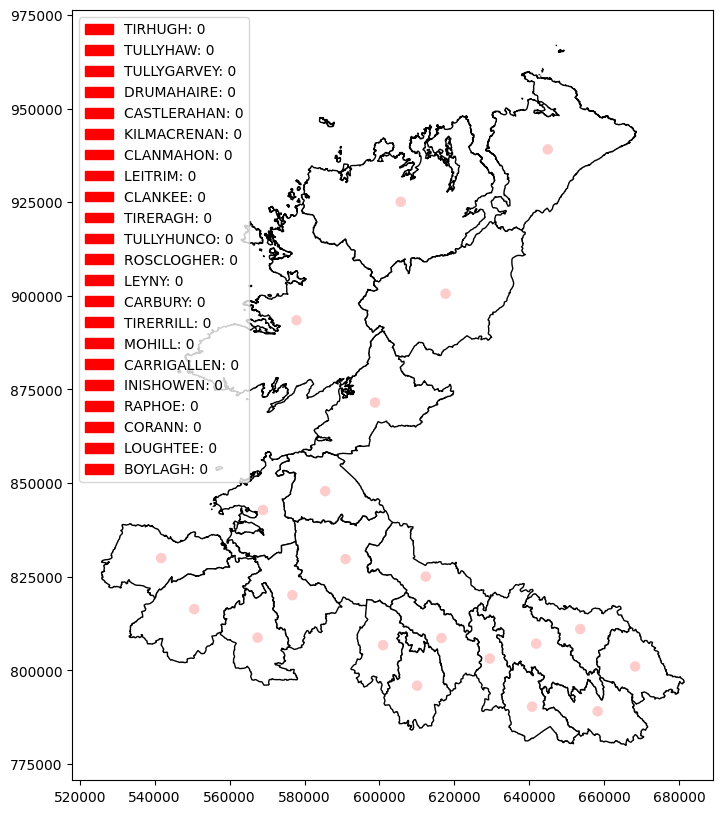

In [ ]:
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(10, 10))

# Plot the territories
tuatha_nw_1600_mod.plot(ax=ax, color='white', edgecolor='black')

# Plot the buffers as transparent circles
buffer_df.plot(ax=ax, color='red', alpha=0.2)

# Create a list to store the legend elements
legend_elements = []

# Loop through each territory and add a patch to the legend elements
for territory in tuatha_nw_1600_mod['ENGLISH'].unique():
    num_monuments = unique_monuments[territory] if territory in unique_monuments else 0
    legend_elements.append(mpatches.Patch(color='red', label=f'{territory}: {num_monuments}'))

# Add the legend to the plot
ax.legend(handles=legend_elements, loc='upper left')

plt.show()

/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_7247/2201655857.py:5: UserWarning: Only one of 'bins' and 'norm' arguments can be supplied, ignoring bins=log
  hb = ax.hexbin(


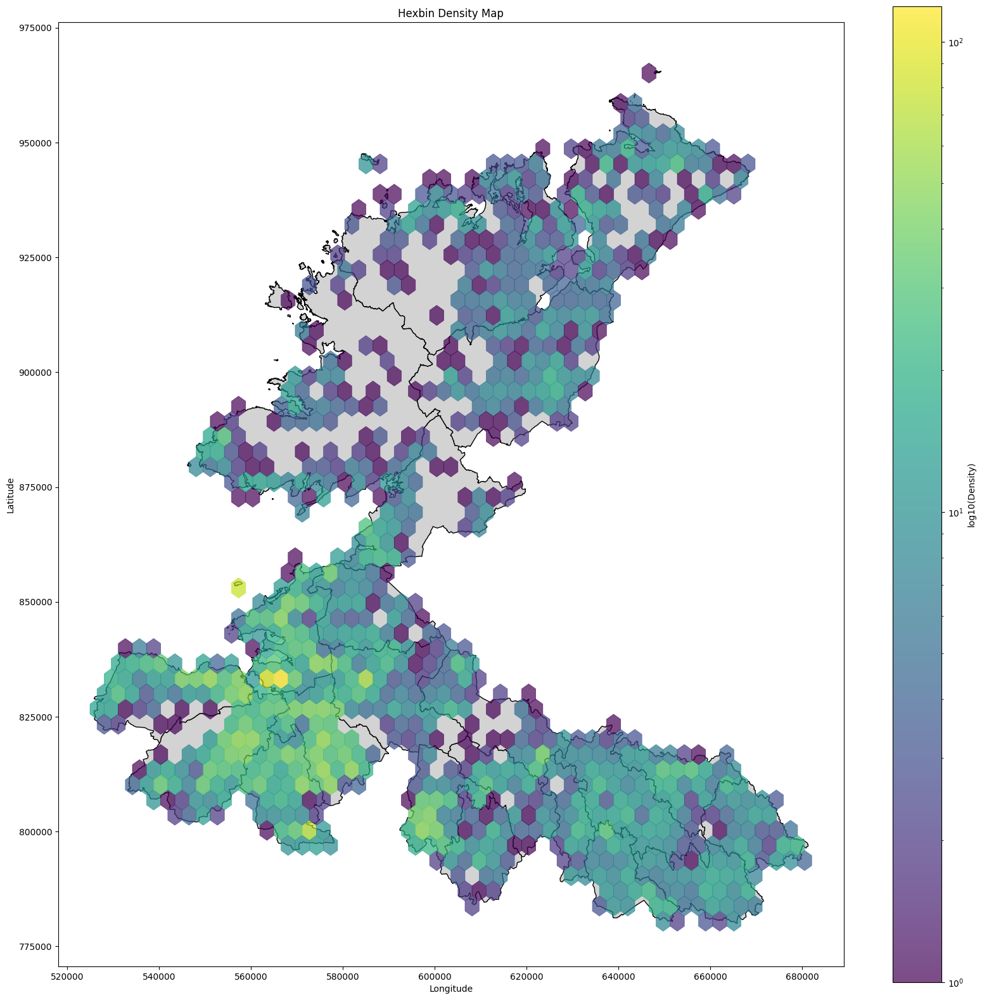

In [ ]:
# Plot the basemap using tuatha_map
ax = tuatha_nw_1600_mod.plot(color='lightgray', edgecolor='black', figsize=(20, 20))

# Create hexbin map for point densities
hb = ax.hexbin(
    sites_nw_clean['geometry'].x,
    sites_nw_clean['geometry'].y,
    gridsize=50,  # Adjust gridsize as needed
    bins='log',   # Apply logarithmic scale to color intensity
    cmap='viridis',  # Choose a colormap
    alpha=0.7,  # Set transparency
    linewidth=0.5,  # Set linewidth for hexagon borders
    norm=LogNorm(),  # Use logarithmic scale for color normalization
)

# Add colorbar
cb = plt.colorbar(hb, ax=ax, label='log10(Density)')

# Add labels, title, or any other customizations
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Hexbin Density Map')

plt.show()



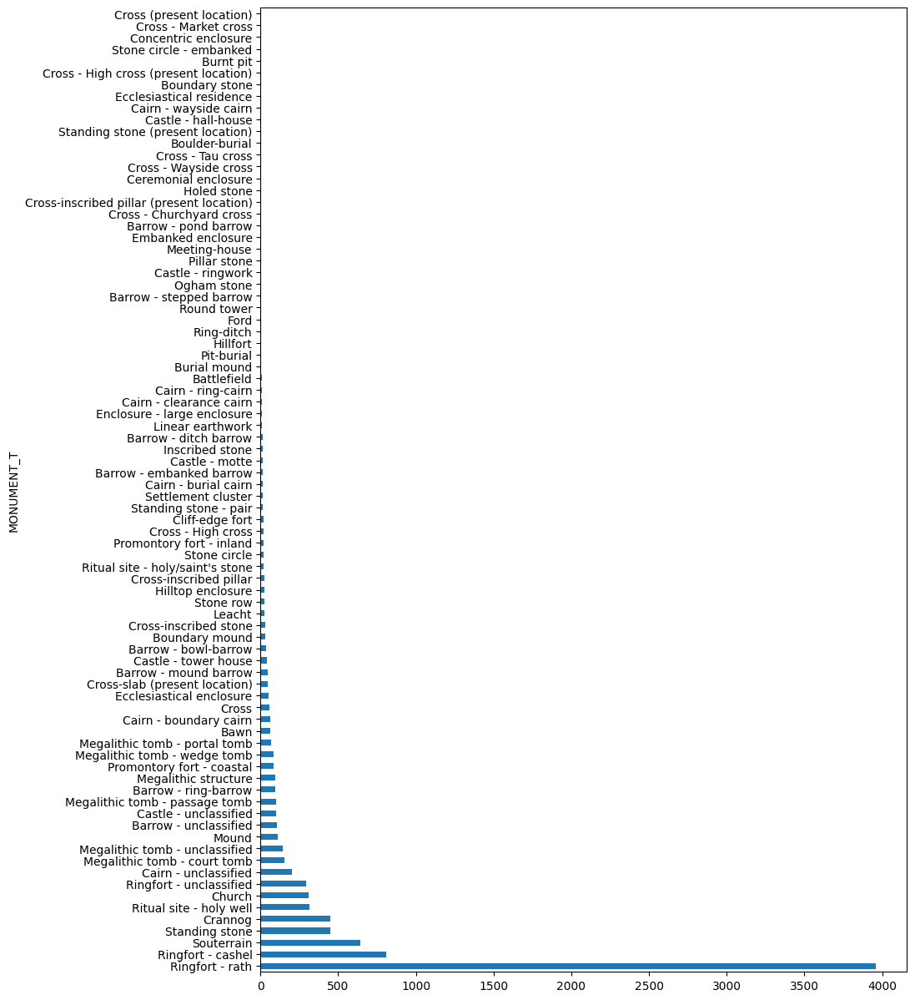

In [ ]:
# List unique values in the sites_nw_clean['MONUMENT_T'] column
sites_nw_clean.MONUMENT_T.unique()
sites_nw_clean['MONUMENT_T'].value_counts()
sites_nw_clean['MONUMENT_T'].value_counts().plot(kind='barh', figsize=(10,15))
plt.show()


In [ ]:
# Here we begin to tidy up the features in the MONUMENT_T column.
# Join Cairn - unclassified and Cairn - boundary cairn together
# sites_nw_clean['MONUMENT_T'] = sites_nw_clean['MONUMENT_T'].replace(['Cairn - unclassified', 'Cairn - boundary cairn'], 'Cairn')

In [11]:
# Extract the sites by type

raths = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Ringfort - rath']
cashels = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Ringfort - cashel']
standing_stones = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Standing stone']
churches = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Church']
tower_houses = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Castle - tower house']
castles = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Castle - unclassified']
crannogs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Crannog']
souterrains = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Souterrain']
boundary_cairns = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Cairn - boundary cairn']
cairns = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Cairn - unclassified']
boundary_mounds = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Boundary mound']
mounds = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Mound']
court_tombs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Megalithic tomb - court tomb']
passage_tombs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Megalithic tomb - passage tomb']
wedge_tombs = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == 'Megalithic tomb - wedge tomb']




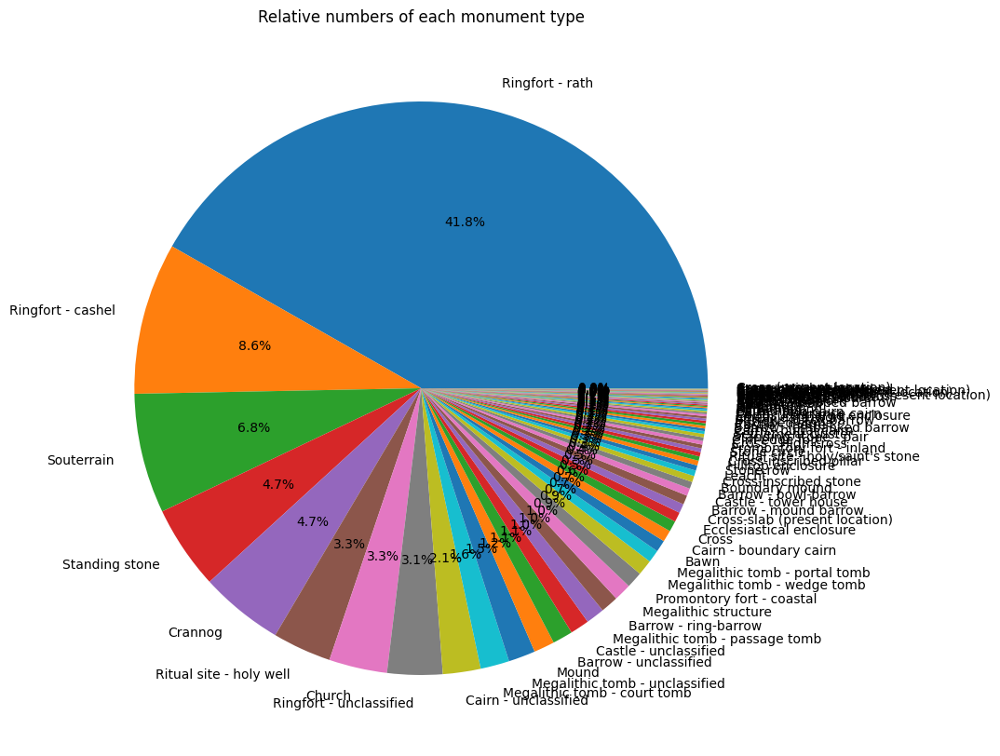

In [12]:
# CREATE PIE CHART OF PROPORTION OF MONUMENT TYPES

# Get the counts of each monument type
monument_counts = sites_nw_clean['MONUMENT_T'].value_counts()

# Create the pie chart
plt.figure(figsize=(10,10))
plt.pie(monument_counts, labels = monument_counts.index, autopct='%1.1f%%')
plt.title('Relative numbers of each monument type')
plt.show()


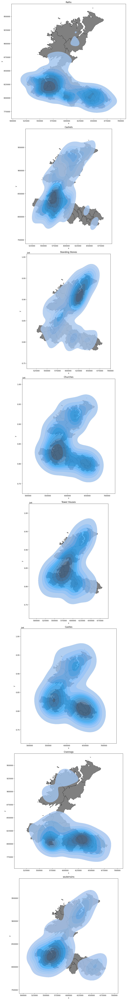

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib.pyplot as plt
import seaborn as sns

# List of monument classes
monument_classes = [raths, cashels, standing_stones, churches, tower_houses, castles, crannogs, souterrains]

# List of monument class names
monument_class_names = ['Raths', 'Cashels', 'Standing Stones', 'Churches', 'Tower Houses', 'Castles', 'Crannogs', 'souterrains']

# Create a subplot for each class
fig, axs = plt.subplots(nrows=len(monument_classes), figsize=(10, 10*len(monument_classes)))

for ax, monument_class, class_name in zip(axs, monument_classes, monument_class_names):
    # Create a new DataFrame with the x and y coordinates of the monument class
    coords = pd.DataFrame({'x': monument_class['geometry'].x, 'y': monument_class['geometry'].y})

    # Plot the basemap
    tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='black', linewidth=0.5)

    # Create the KDE plot
    sns.kdeplot(data=coords, x='x', y='y', ax=ax, fill=True, alpha=0.8)

    # Set the title
    ax.set_title(class_name)

plt.tight_layout()
plt.show()

In [ ]:
# Load the rivers , parishes and townlands shapefiles
rivers = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/rivers_nw.shp')
parishes_nw = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/parishes_nw.shp')
townlands_nw = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/townlands_nw.shp')

In [ ]:
# Soils data
soils = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/soils_map_nw.shp')
soils.head()

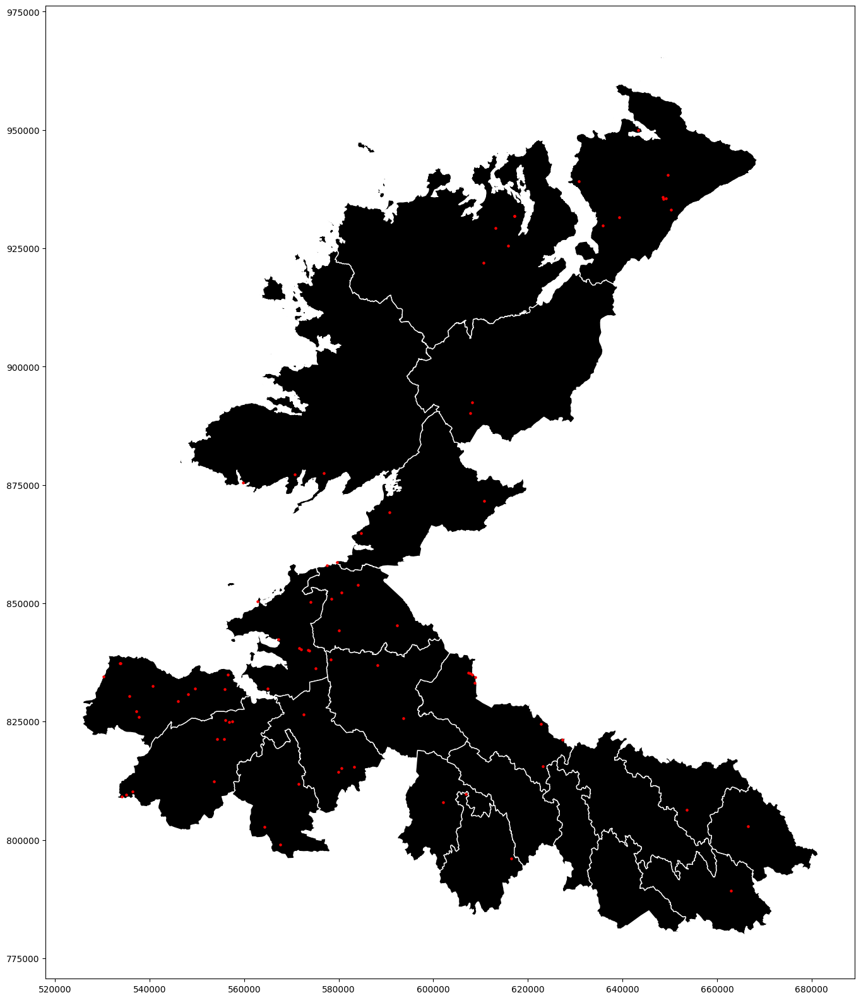

In [ ]:
# Plot the wegde tombs
ax = tuatha_nw_1600_mod.plot(color='black', edgecolor='white', figsize=(20, 20))
wedge_tombs.plot(ax=ax, color='red', markersize=5)
plt.show()



Number of intersections: 38
Number of objects: 83
Percentage of objects intersecting with a boundary: 45.78%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
149     Situated in a forest on a hill overlooking Lou...
154     Situated on a hilltop and is surrounded by tre...
160     This is 30m E of the court tomb in the same to...
214     Situated in an open space in a plantation on t...
255     Originally sited on Church Hill at the SE flan...
328     Sited on a slight rise in undulating land. Thi...
1854    'The site consists of the remains of a gallery...
1867    The Archaeological Survey of Ireland (ASI) is ...
1937    The monument stands on level ground toward the...
2005    This monument lies 2km W of Bundoran, just 50m...
2208    The monument is on the summit of a hill, close...
2441    The monument is 1.5km from the E side of Lough...
3337    This monument is c. 200m E of and overlooking ...
3341    This monument is on a level patch of poor past...
3372    This monu

NameError: name 'parishes_nw' is not defined

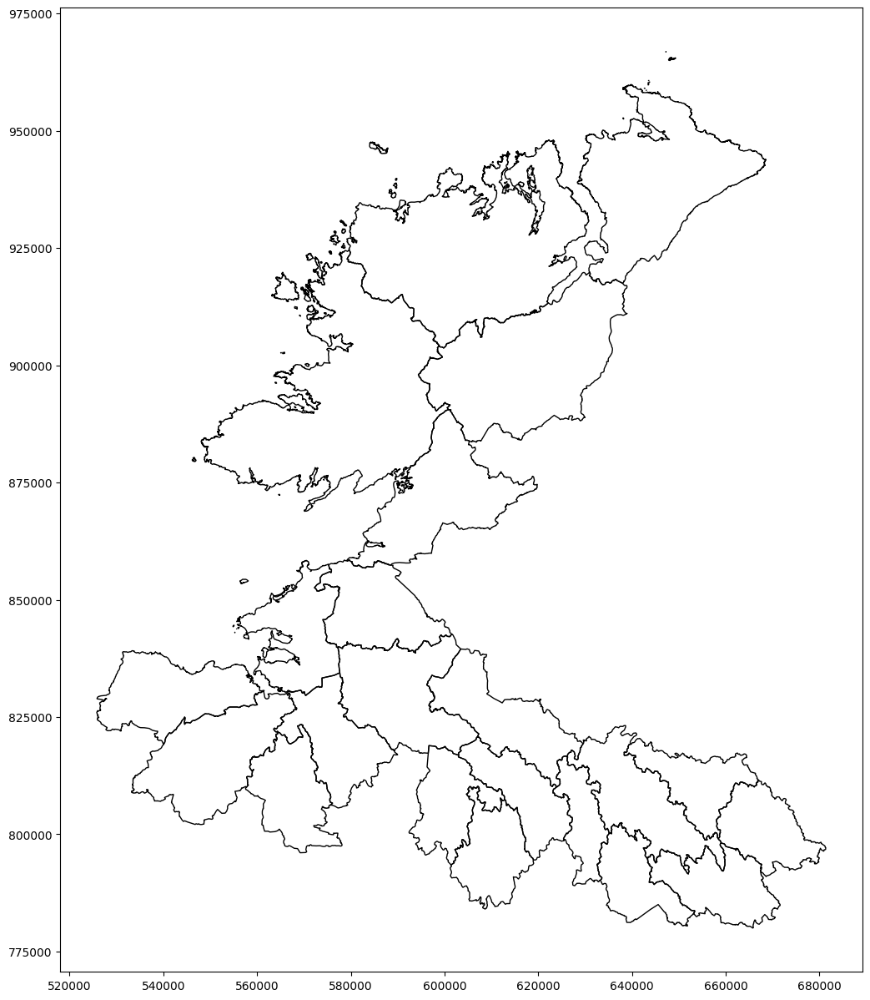

In [25]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = wedge_tombs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
wedge_tombs.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.4)

plt.show()

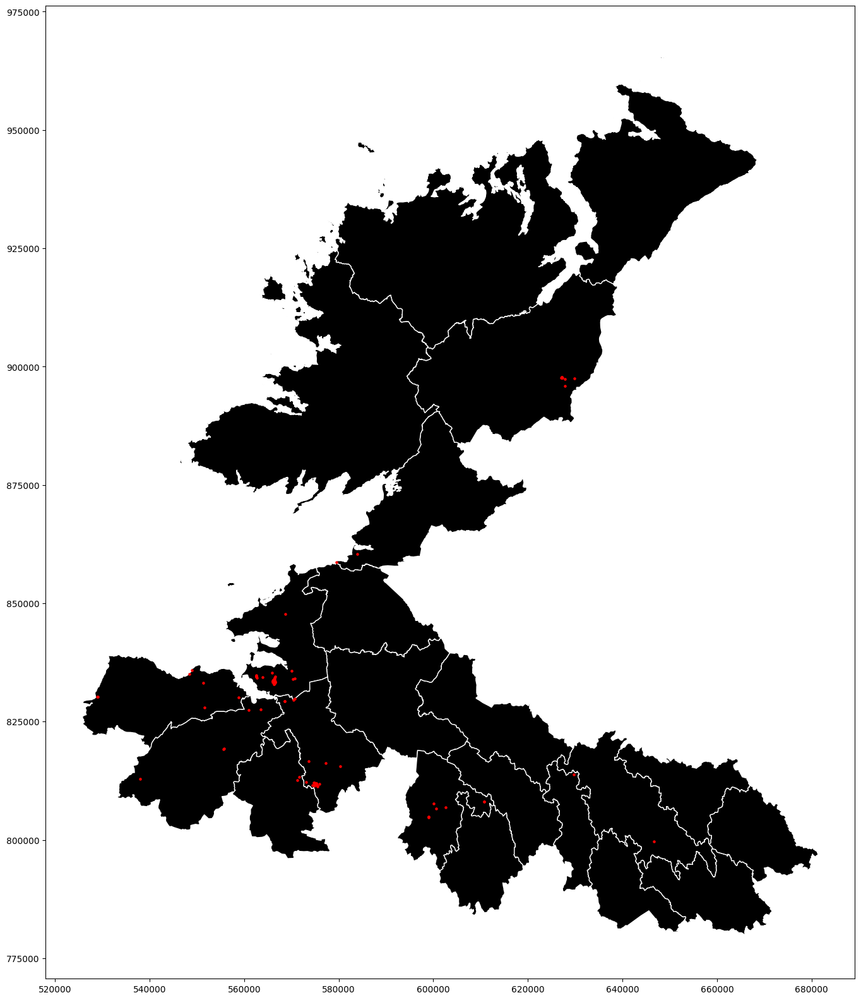

In [ ]:
# Plot the Passages Tombs
ax = tuatha_nw_1600_mod.plot(color='black', edgecolor='white', figsize=(20, 20))
#parishes_nw.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)
passage_tombs.plot(ax=ax, color='red', markersize=10)
plt.show()




Number of intersections: 45
Number of objects: 99
Percentage of objects intersecting with a boundary: 45.45%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
363     Situated on the summit of a ridge and with com...
3009    This monument stands within a hillfort (Lacy 1...
3511    This monument is an undifferentiated passage t...
3605    The remains of a cruciform passage tomb surviv...
4696    Situated on a rise in an area of rock outcrop ...
4697    Situated on a local prominence in pasture and ...
6122    Situated at the break of the slope on the S si...
6405    See linked document with details from Seán Ó N...
6410    See linked document (SL020-129----_01.pdf) wit...
6547    Located on a low N-S elevation, on the summit ...
6548    On the summit of Knocknarae Mountain, located ...
6550    This massive circular, limestone cairn (diam. ...
6552    On the summit of Knocknarae Mountain, located ...
6555    On a broad terrace below and to SE of the summ...
6562    Located o

NameError: name 'parishes_nw' is not defined

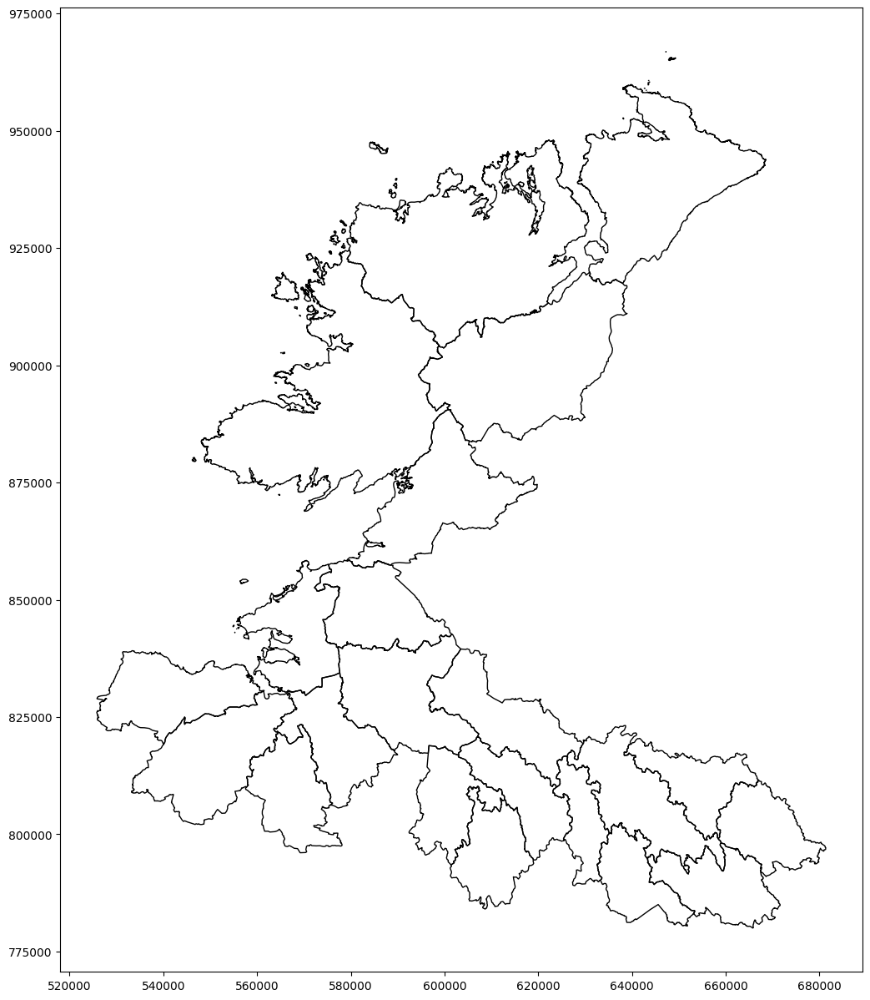

In [26]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = passage_tombs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
passage_tombs.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.4)

plt.show()

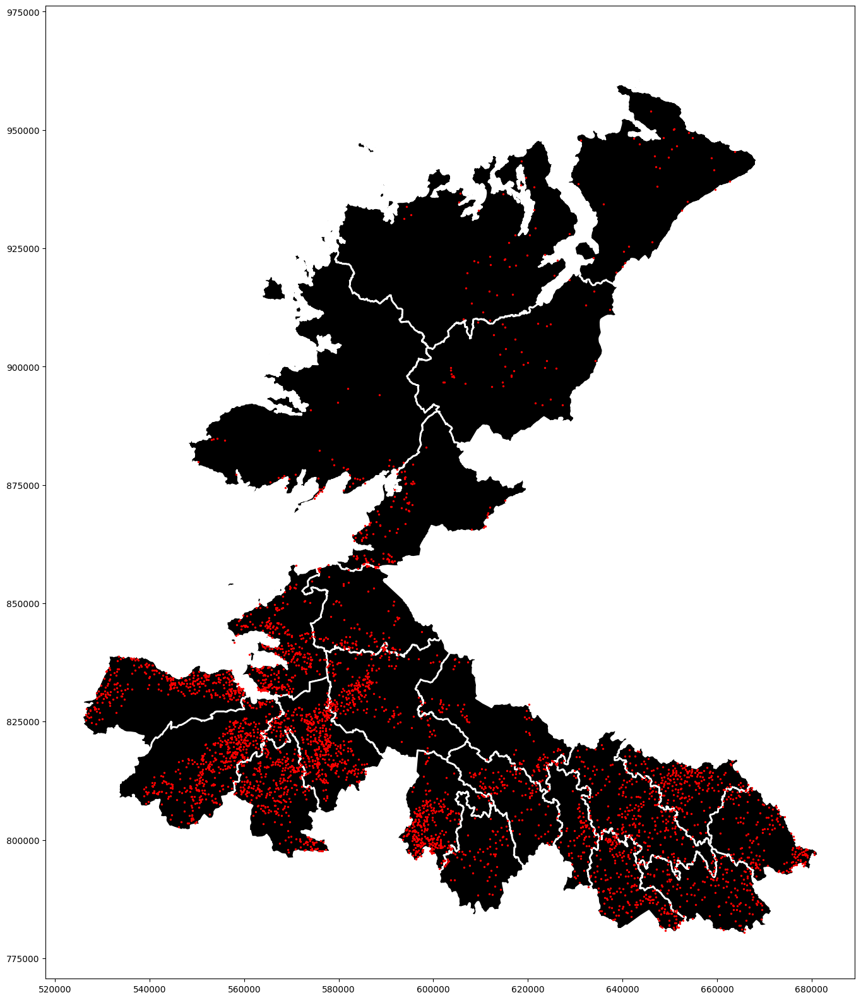

In [ ]:
# Plot the RATHS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=2)
#townlands_nw.plot(ax=ax, color='black', edgecolor='white', alpha=0.5, linewidth=0.5)
#rivers.plot(ax=ax, color='blue')    
raths.plot(ax=ax, color='red', markersize=2)
plt.show()


Number of intersections: 2134
Number of objects: 3961
Percentage of objects intersecting with a boundary: 53.88%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
5       Raised circular area (int. diam 37.5m) enclose...
6       Probably originally a rath later transformed i...
7       Probably originally a rath later transformed i...
8       Raised oval area (int. dims. 48.8m N-S; 32.7m ...
9       An earlier report (OPW 1970) described a raise...
                              ...                        
9430    In lowlying pasture, at the narrow S corner of...
9433    In pasture, crowning the summit of a steep-sid...
9450    Situated in a col with slightly higher ground ...
9456    Located at the bottom of a gentle E-facing slo...
9481    In good coastal grassland, 1km S of Ballysadar...
Name: WEB_NOTES, Length: 2134, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([   5,    6,    7,    8,    9,   11,   13,   21,   22,   27,
       ..

NameError: name 'parishes_nw' is not defined

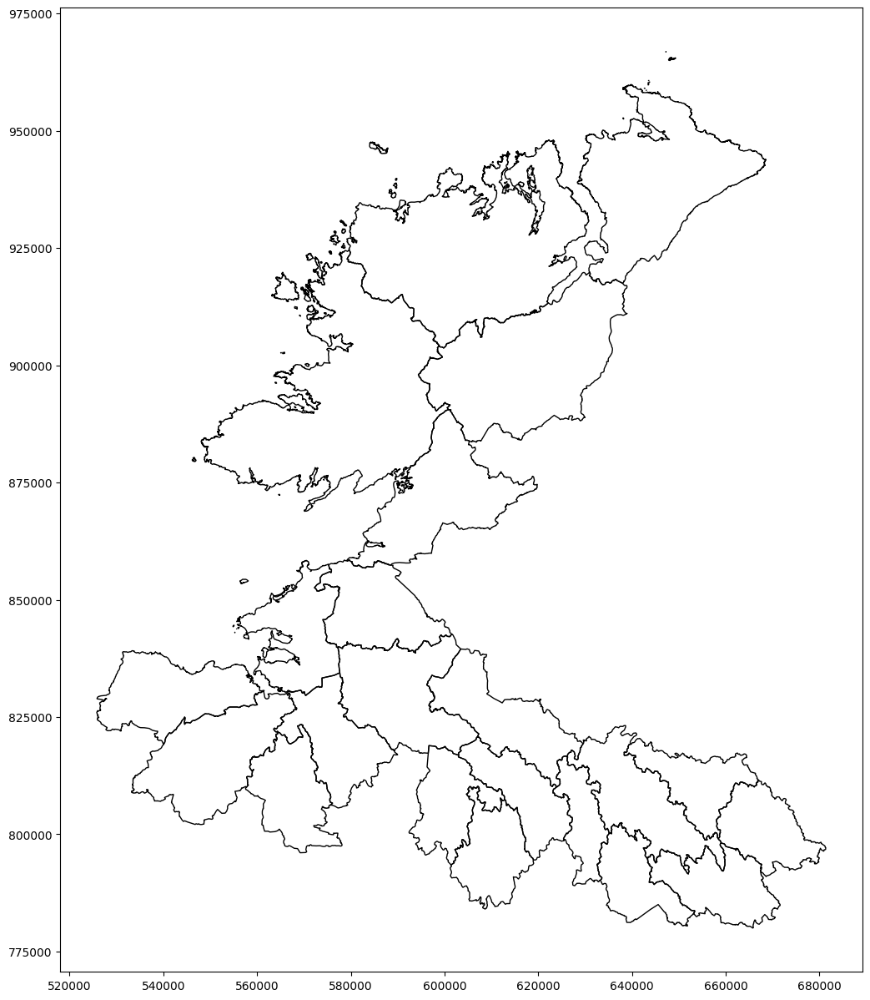

In [27]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = raths # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
raths.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.4)

plt.show()

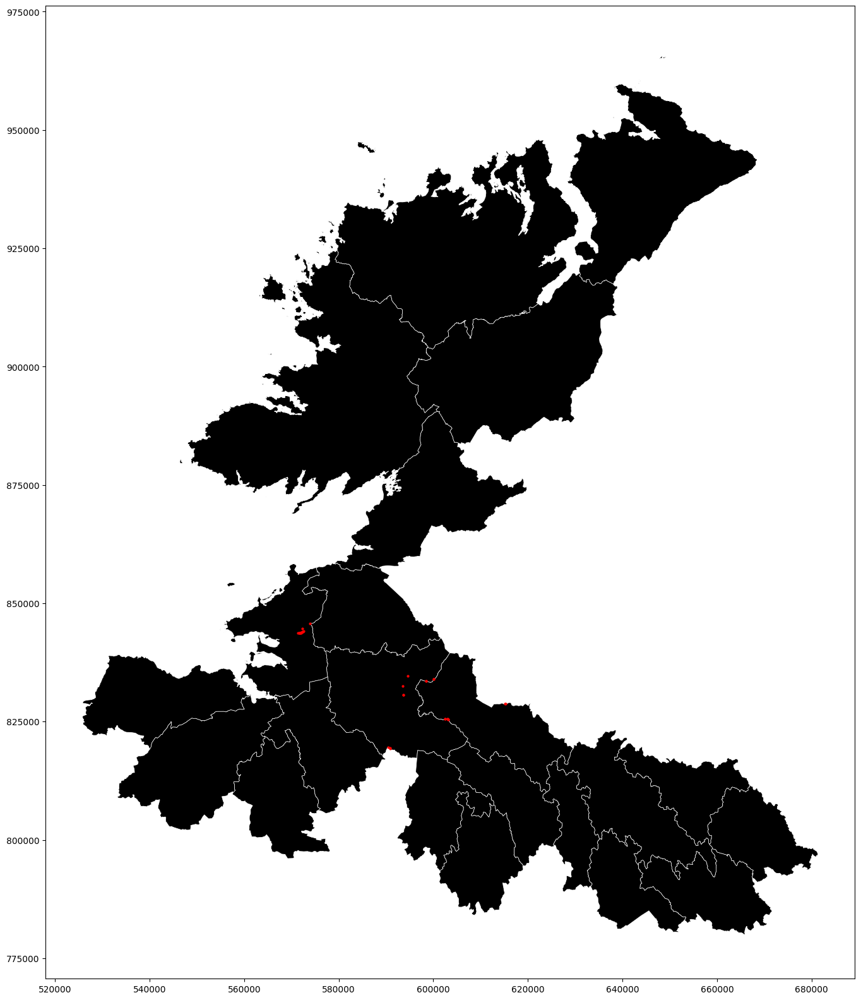

In [ ]:
# Plot the Boundary mounds on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax,color="black", edgecolor='white', linewidth=0.5)
boundary_mounds.plot(ax=ax, color='red', markersize=4)
plt.show()


Number of intersections: 17
Number of objects: 33
Percentage of objects intersecting with a boundary: 51.52%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
152     Not marked on OS 1836 or 1876 eds. Situated on...
178     Not marked on OS 1836 or 1876 eds. Situated on...
182     Not marked on OS 1836 or 1876 eds. Situated on...
216     In rough mountainous terrain. One of a series ...
217     In rough mountainous terrain. One of a series ...
1883    About 40 mounds in a SW-NE line are marked onl...
1884    About 80 mounds in a WNW-ESE line are marked o...
4263    About 80 mounds in a WNW-ESE line are marked o...
4545    Marked only on the 1907 edition of the OS 6-in...
4546    Marked only on the 1907 edition of the OS 6-in...
5132    Marked only on the 1914 edition of the Roscomm...
5133    Situated on a broad E-W ridge. It is marked on...
5227    About 40 mounds in a SW-NE line are marked onl...
5233    Situated on a broad E-W ridge. It is marked on...
5885    Listed in

NameError: name 'parishes_nw' is not defined

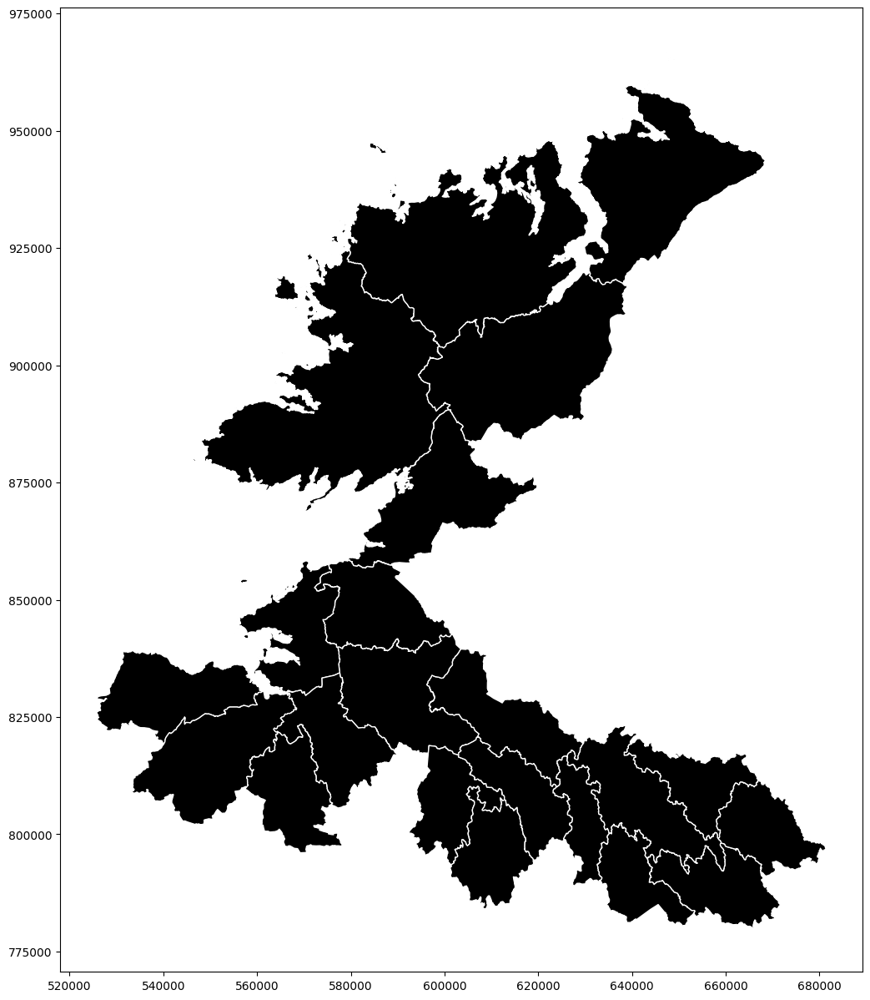

In [28]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = boundary_mounds # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.plot(ax=ax, color='black', edgecolor="white", linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
boundary_mounds.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

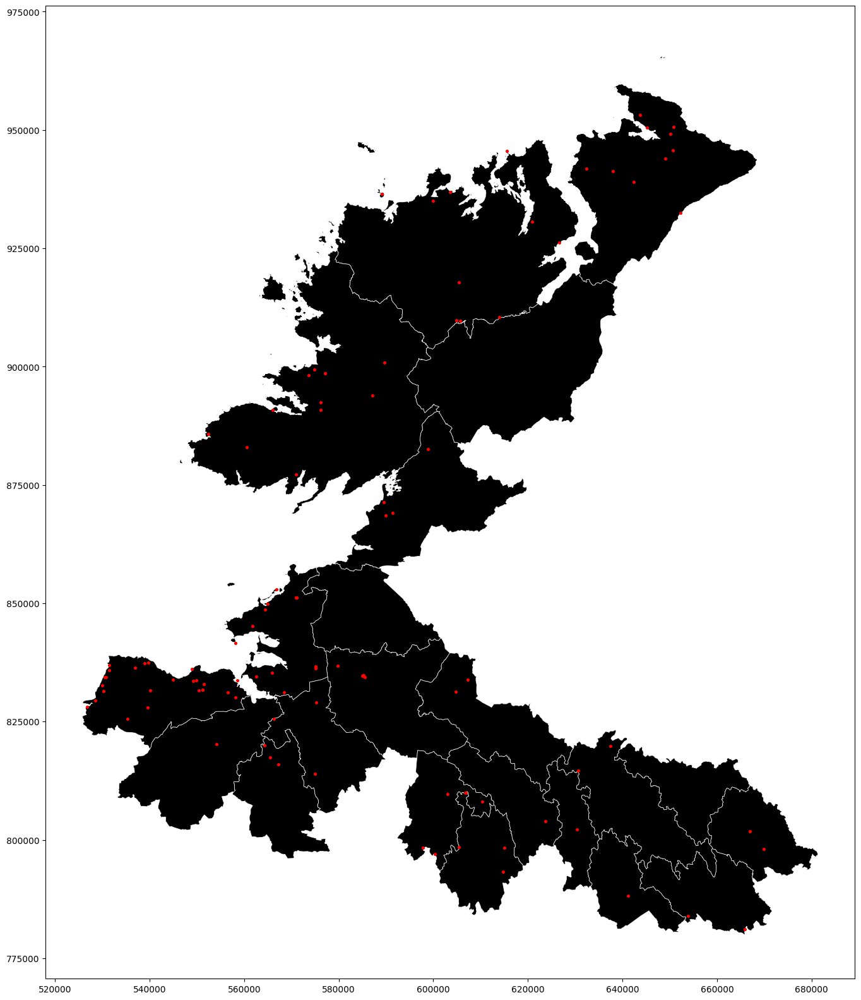

In [ ]:
# Plot the mounds on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax,color="black", edgecolor='white', linewidth=0.5)
mounds.plot(ax=ax, color='red', markersize=7)
plt.show()


Number of intersections: 63
Number of objects: 111
Percentage of objects intersecting with a boundary: 56.76%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
1721    The Archaeological Survey of Ireland (ASI) is ...
1788    A roughly circular round-topped, grass-covered...
1797    The Archaeological Survey of Ireland (ASI) is ...
1802    The Archaeological Survey of Ireland (ASI) is ...
1874    The Archaeological Survey of Ireland (ASI) is ...
                              ...                        
9268    In pasture, on the top of a broad low hill. Gr...
9269    In pasture, located on top of a steep slope wh...
9305    The Archaeological Survey of Ireland (ASI) is ...
9375    In pasture, located at Raghly Point on the SE ...
9472    Reported (5-10-2021) by Mr Aidan Harte, Projec...
Name: WEB_NOTES, Length: 63, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([1721, 1788, 1797, 1802, 1874, 1912, 1923, 1994, 2175, 2331, 2374, 2461,
  

NameError: name 'parishes_nw' is not defined

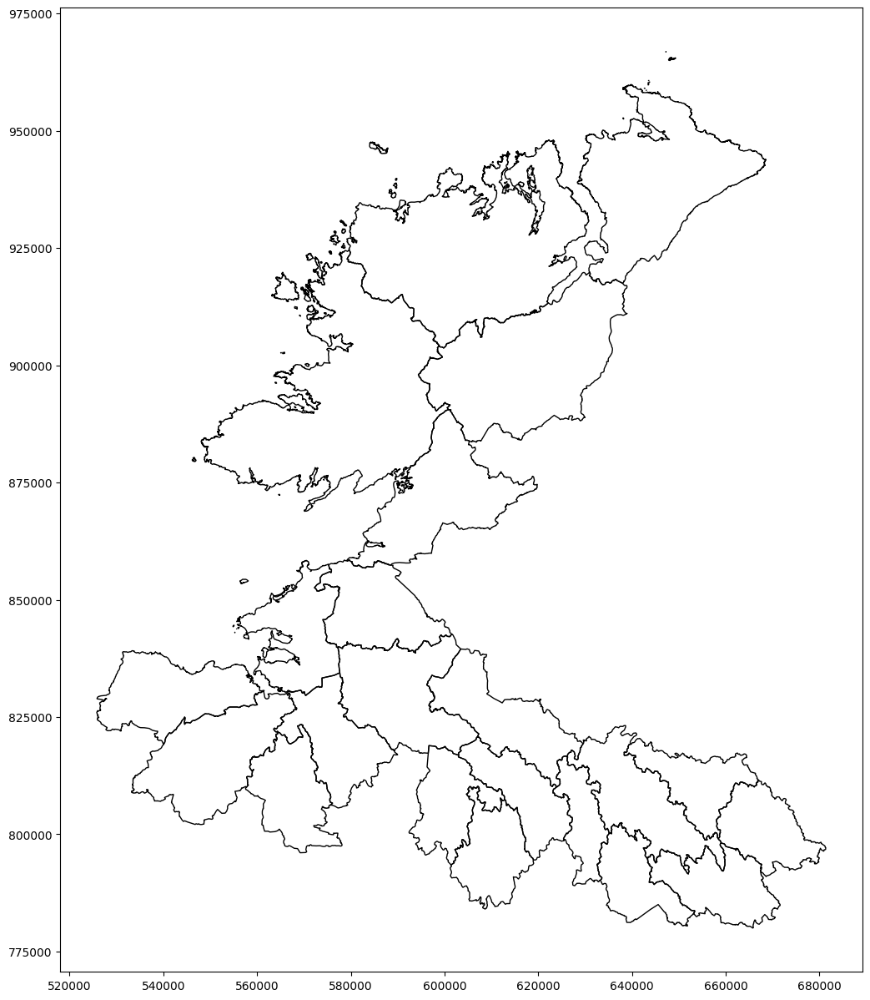

In [29]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = mounds # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
mounds.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

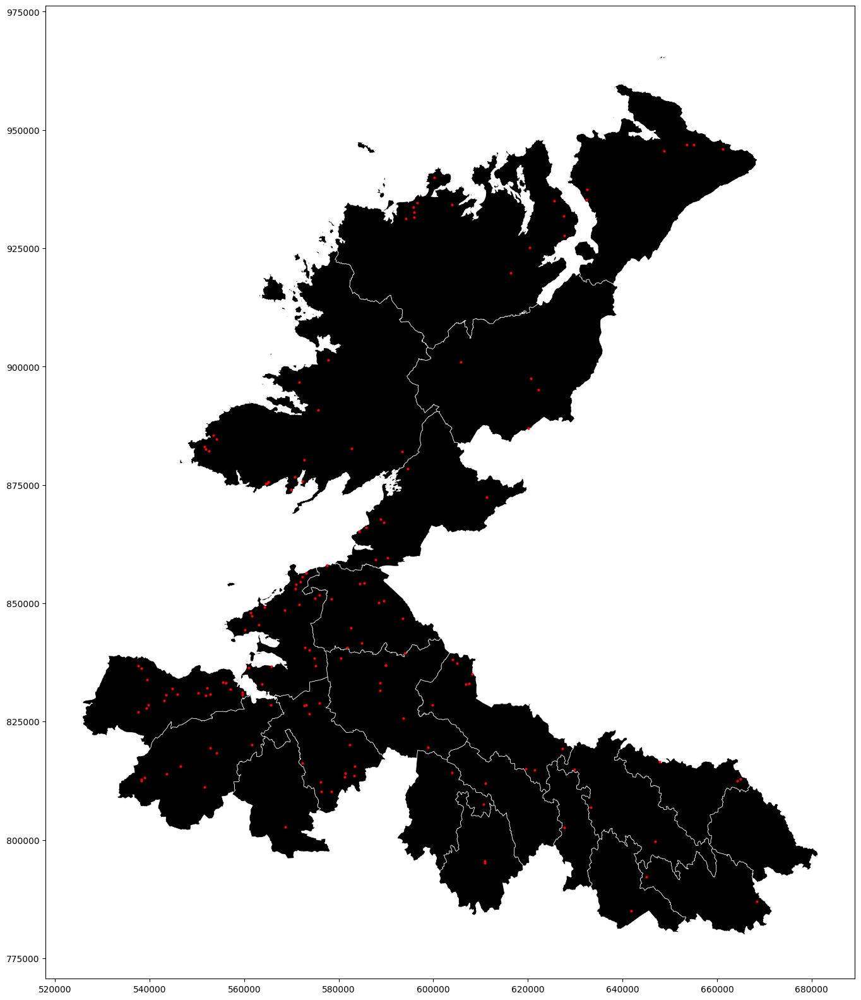

In [ ]:
# Plot the court tombs on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)   
#rivers.plot(ax=ax, color='blue', markersize=1) 
court_tombs.plot(ax=ax, color='red', markersize=10)
plt.show()

plt.show()

Number of intersections: 82
Number of objects: 154
Percentage of objects intersecting with a boundary: 53.25%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
115     Situated on elevated ground S of Lough Macnean...
125     Situated near the top of a low ridge overlooki...
156     Situated about 230m S of Garvagh Lough on poor...
159     Situated on a hill-ridge and close to the wedg...
172     Sited on a small knoll 450m W of the River Sha...
                              ...                        
8709    On a little plateau towards the S end of the B...
8716    On a low ridge close to the W shore of Lough A...
9082    The Archaeological Survey of Ireland (ASI) is ...
9272    Situated on the north side of Glencolumkille v...
9429    Situated on a slight W-E spur on a shelf that ...
Name: WEB_NOTES, Length: 82, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([ 115,  125,  156,  159,  172,  262,  322,  361,  505,  632,  636,  673,
  

NameError: name 'parishes_nw' is not defined

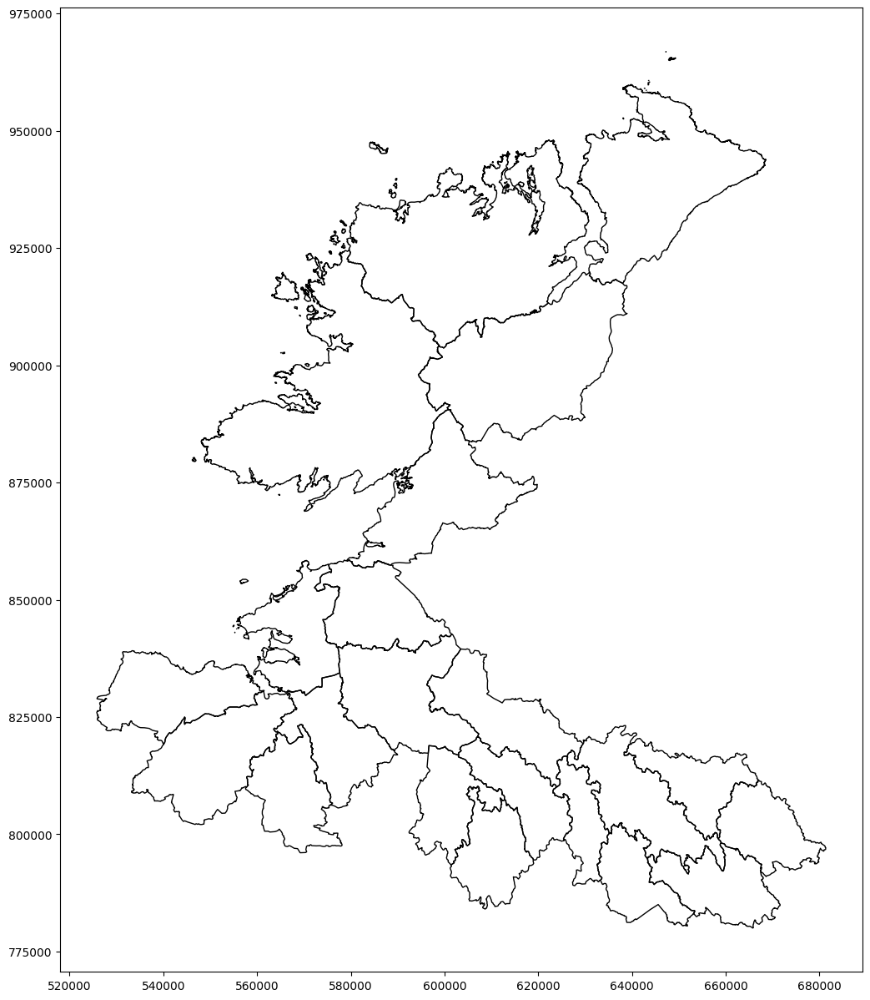

In [30]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = court_tombs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
court_tombs.plot(ax=ax, color='black', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

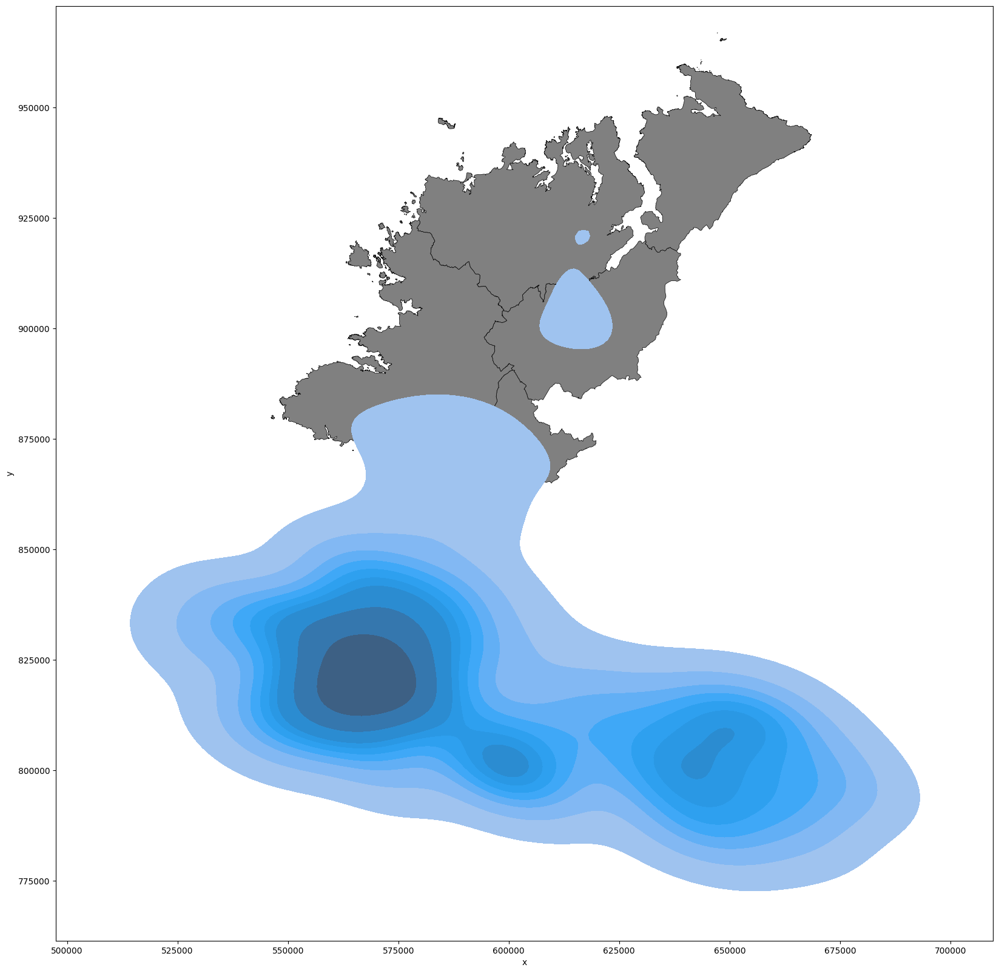

In [ ]:
# Create a KDE plot

# Create a new DataFrame with the x and y coordinates of the raths
raths_coords = pd.DataFrame({'x': raths['geometry'].x, 'y': raths['geometry'].y})

# Plot the basemap
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='black', linewidth=0.5)

# Create the KDE plot
sns.kdeplot(data=raths_coords, x='x', y='y', ax=ax, fill=True)

plt.show()



 


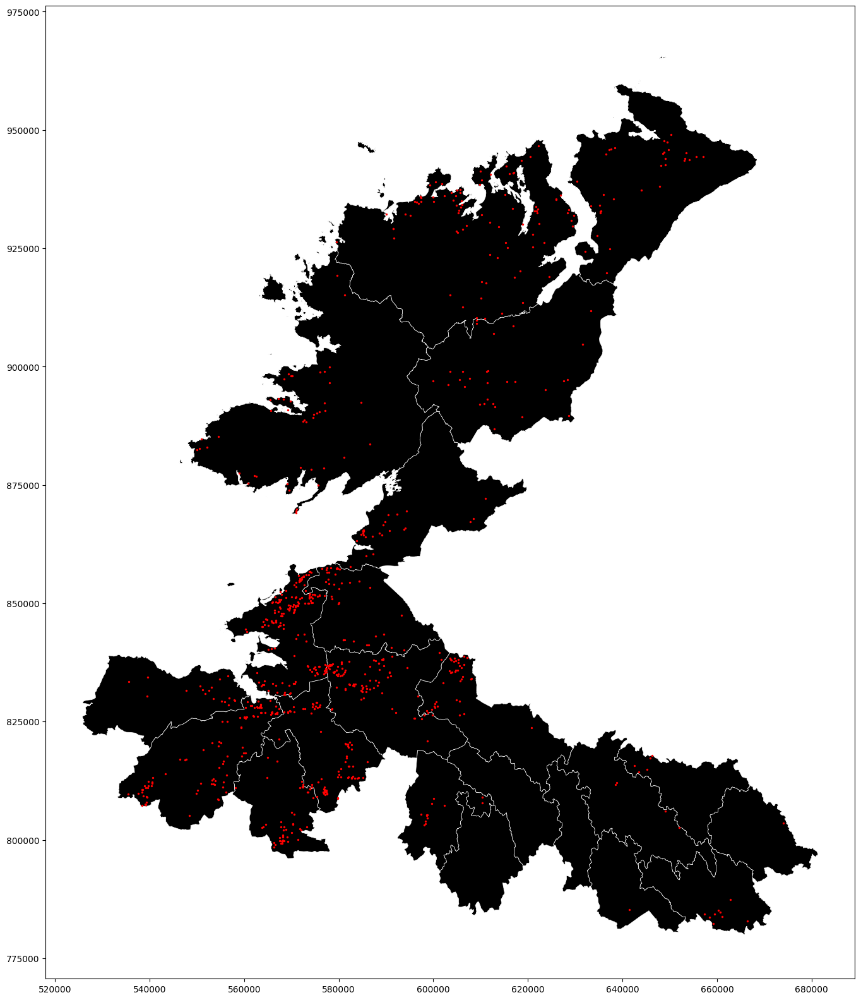

In [ ]:
# Plot the CASHELS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20),)
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
cashels.plot(ax=ax, color='red', markersize=2, )
plt.show()

Number of intersections: 437
Number of objects: 811
Percentage of objects intersecting with a boundary: 53.88%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
94      Not marked on OS 1836 or 1876 eds. Raised circ...
116     Marked 'Fort' on OS 1836 and 1876 eds. Circula...
120     Not marked on OS 1836 or 1876 eds. Raised circ...
121     Indicated on all OS eds. Raised circular area ...
122     Indicated on all OS eds. Raised circular area ...
                              ...                        
9264    On a SE-facing slope overlooking Lough Anure. ...
9371    In pasture, in the SW corner of a field, locat...
9414    Located on a level terrace on the steep W-faci...
9443    In the NE corner of a modern subrectangular pa...
9452    In pasture, located on a terrace on a NW-facin...
Name: WEB_NOTES, Length: 437, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  94,  116,  120,  121,  122,  123,  126,  129,  132,  133,
       ...
 

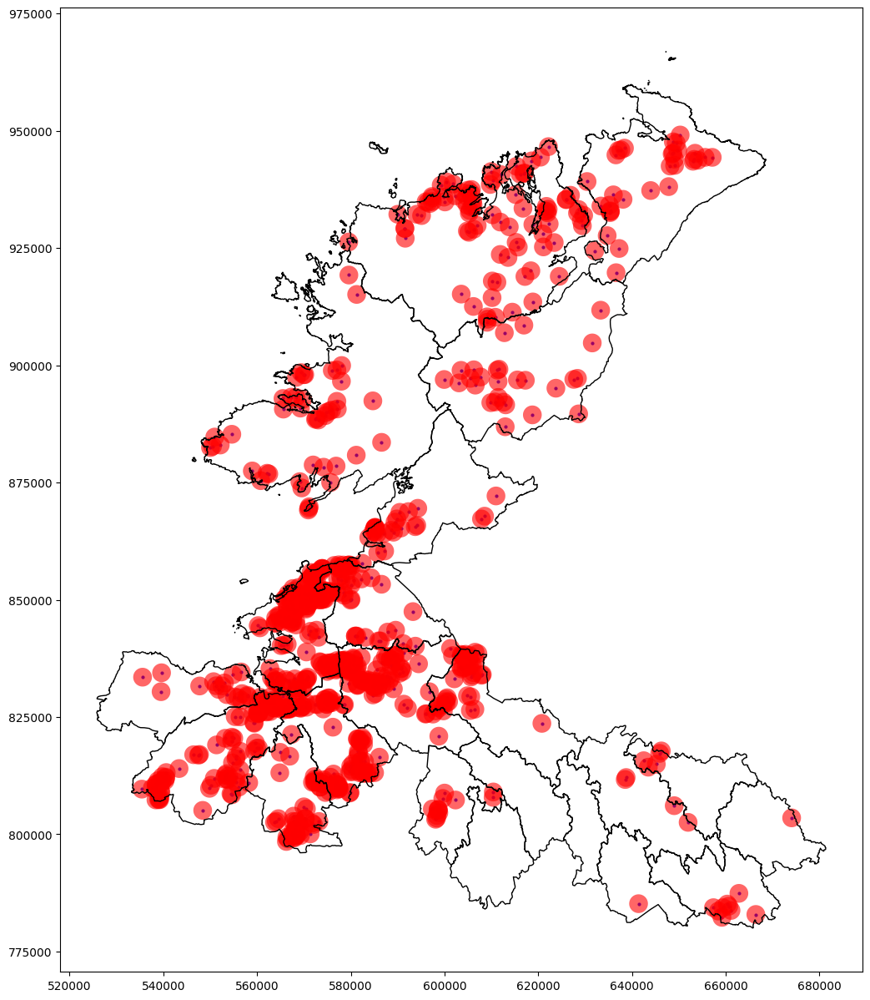

In [31]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = cashels # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)

# Plot the data points
cashels.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

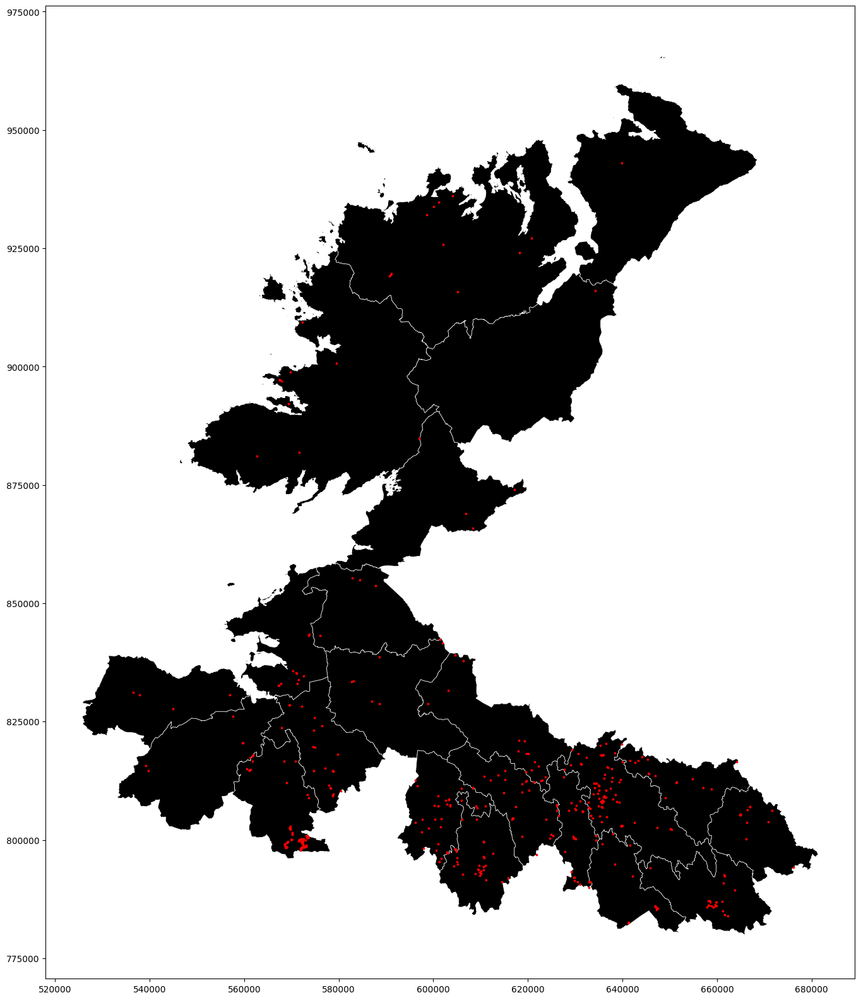

In [ ]:
# Plot the CRANNOGS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
crannogs.plot(ax=ax, color='red', markersize=3)
plt.show()

Number of intersections: 254
Number of objects: 447
Percentage of objects intersecting with a boundary: 56.82%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
26      Subcircular island (diam. c. 20m) in Lough Gow...
97      An almost circular tree-and-grass-covered isla...
109     The Archaeological Survey of Ireland (ASI) is ...
110     The Archaeological Survey of Ireland (ASI) is ...
111     The Archaeological Survey of Ireland (ASI) is ...
                              ...                        
9471    Situated just off the S shore of Mill Lough, a...
9473    Located c. 40m from the SE shore of the rectan...
9474    Located towards the W end of the teardrop-shap...
9476    A small island (diam. c. 10m) is depicted only...
9477    Located in a small U-shaped bay (dims c. 90m E...
Name: WEB_NOTES, Length: 254, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  26,   97,  109,  110,  111,  136,  250,  267,  274,  275,
       ...
 

NameError: name 'parishes_nw' is not defined

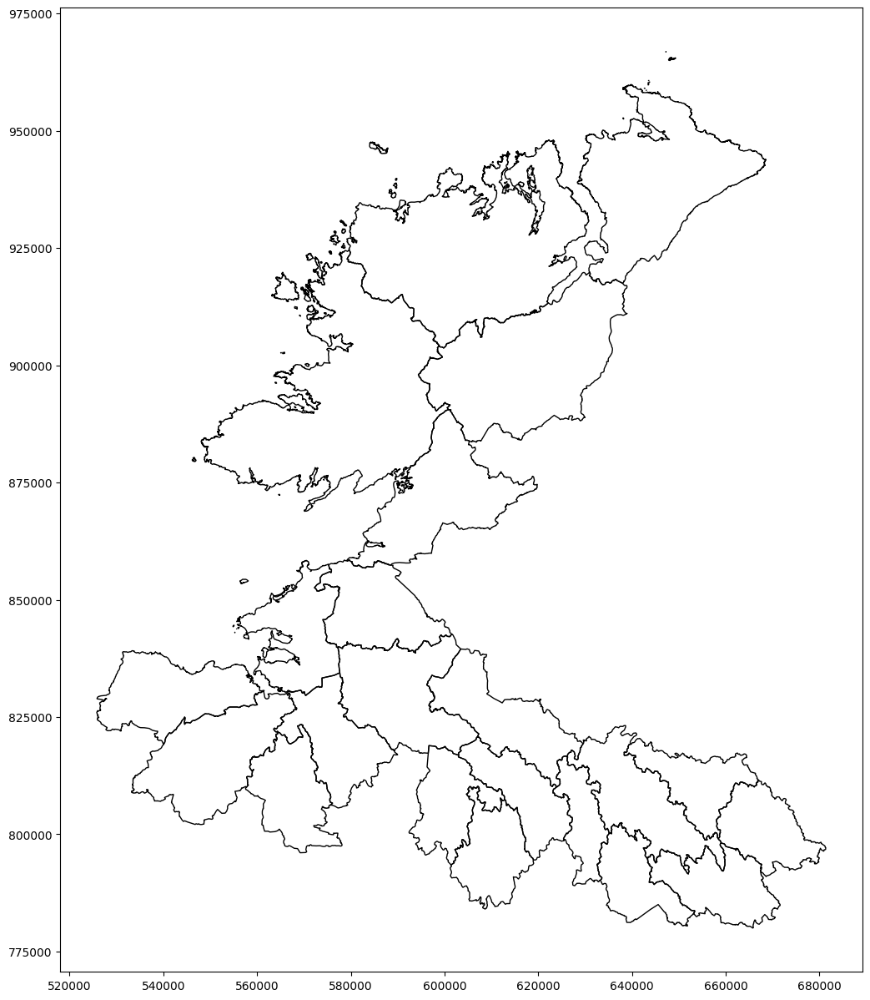

In [32]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = crannogs # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.boundary.plot(ax=ax, color='black', linewidth=0.5)

# Plot the data points
crannogs.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

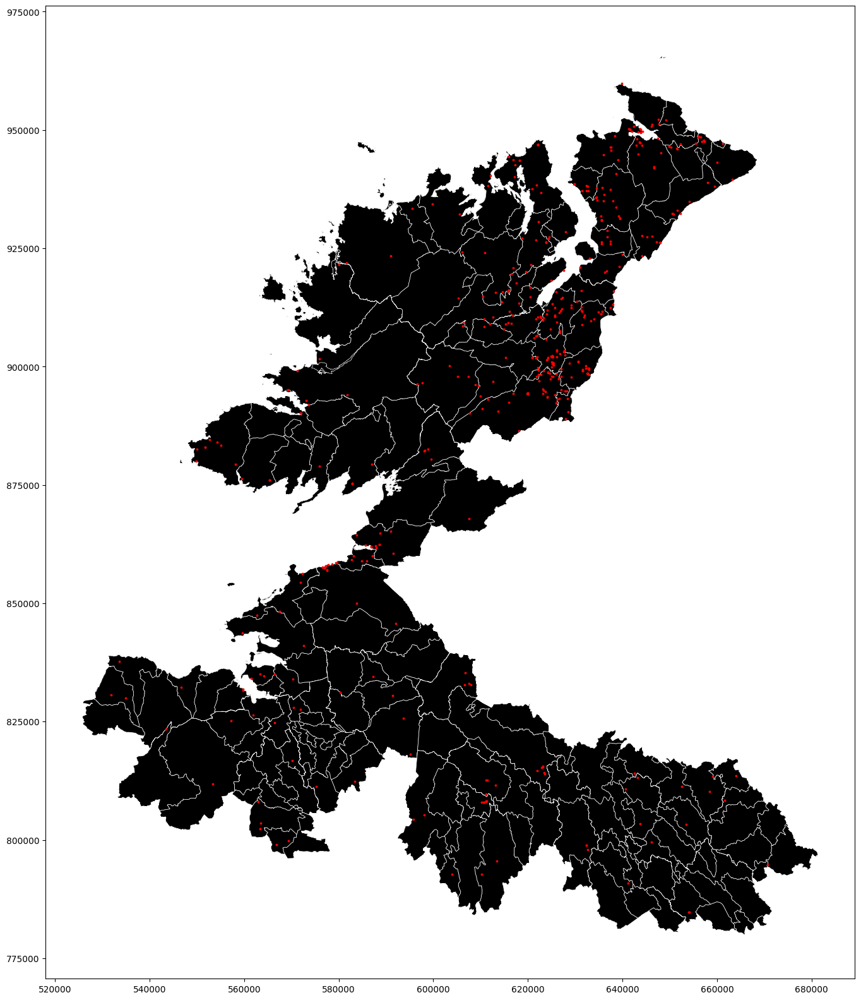

In [ ]:
# Plot the standing stones on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)  
parishes_nw.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5) 
standing_stones.plot(ax=ax, color='red', markersize=3)
plt.show()

CHURCHES

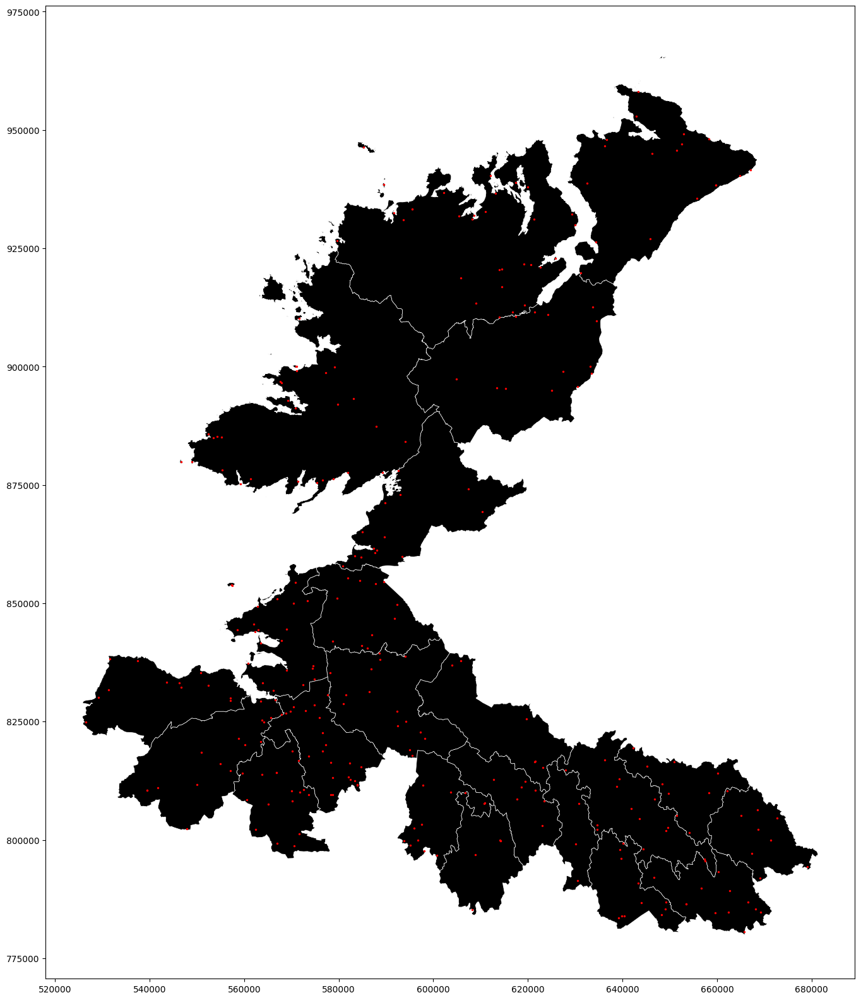

In [ ]:
# Plot the churches on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)   
#parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)
churches.plot(ax=ax, color='red', markersize=2)
plt.show()



Number of intersections: 204
Number of objects: 311
Percentage of objects intersecting with a boundary: 65.59%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
10      Davies (1948, 110) speculated that this childr...
23      Davies (1948, 109) suggested that this was an ...
24      Marked 'Fort', with a 'Church' indicated withi...
108     Described in the Inventory of Irish Architectu...
131     Rectangular church (int. dims. 20.8m E-W; 5.8m...
                              ...                        
9047    In a small grove of trees on top of a low rise...
9086    The Archaeological Survey of Ireland (ASI) is ...
9233    A well (DG027-019----) which is depicted on th...
9238    A small rectangular disused graveyard (DG079-0...
9260    Situated in Ballynacarrow village, on the NW s...
Name: WEB_NOTES, Length: 204, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  10,   23,   24,  108,  131,  225,  330,  401,  533,  556,
       ...
 

NameError: name 'parishes_nw' is not defined

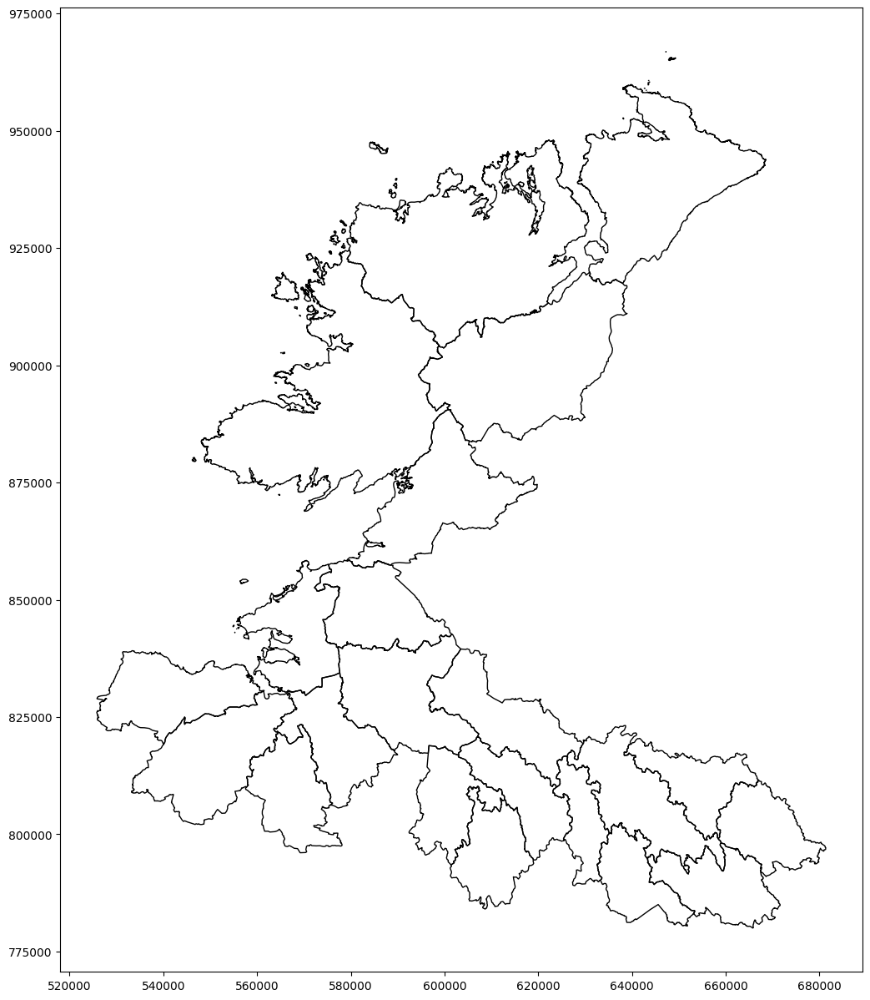

In [33]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = churches # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
churches.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

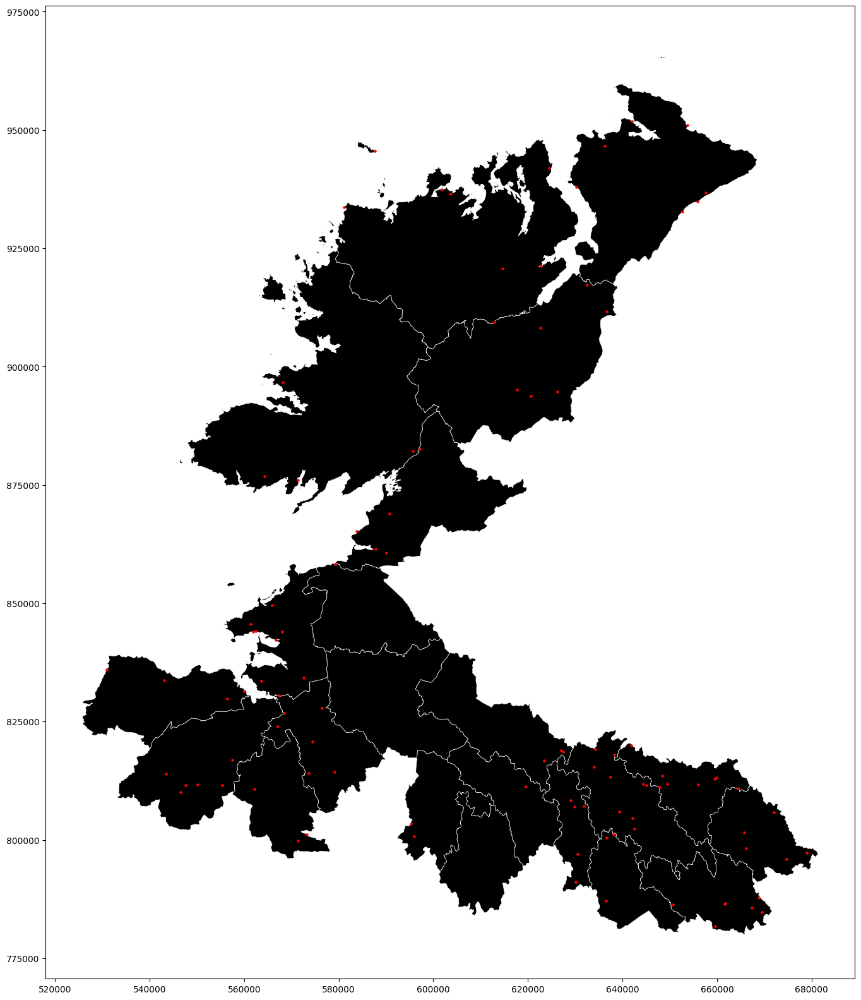

In [ ]:
# Plot the castles on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
castles.plot(ax=ax, color='red', markersize=5)
plt.show()

Number of intersections: 69
Number of objects: 102
Percentage of objects intersecting with a boundary: 67.65%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
14      Davies (1948a, 115) recorded the site of a pla...
93      Reputed to be the site of a 16th-century O'Rei...
248     Captain Culme and Walter Talbot were granted 1...
257     Built by Sir Hugh Wirrall in 1618, subsequentl...
259     Henry (1987, 23) writing in 1739 recorded a re...
                              ...                        
7441    In a meadow, on top of a rise. There are now n...
8035    In rough pasture, on slightly raised level gro...
8062    In low-lying level terrain. There are no visib...
8920    In the SE quadrant of a moated site (SL045-007...
8984    In rough pasture, at Castle Point which is the...
Name: WEB_NOTES, Length: 69, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  14,   93,  248,  257,  259,  270,  281,  338,  468,  512,  513,  549,
  

NameError: name 'parishes_nw' is not defined

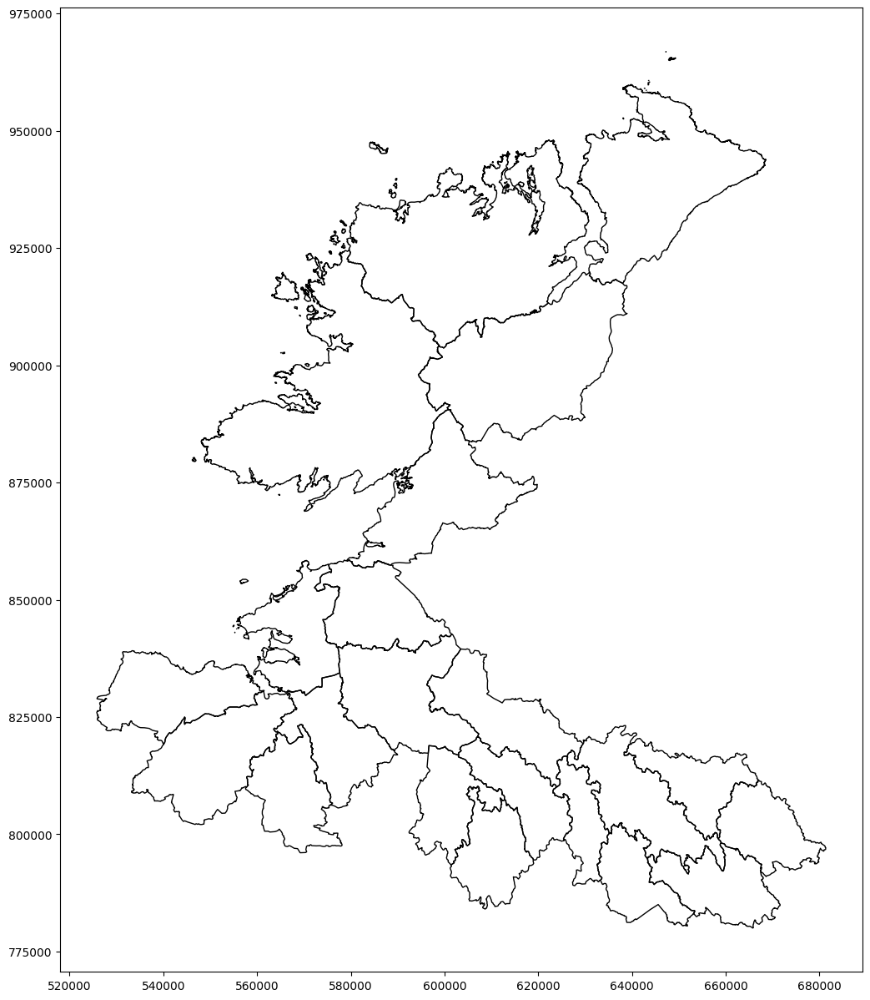

In [34]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = castles # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer




num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
castles.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

TOWER HOUSES


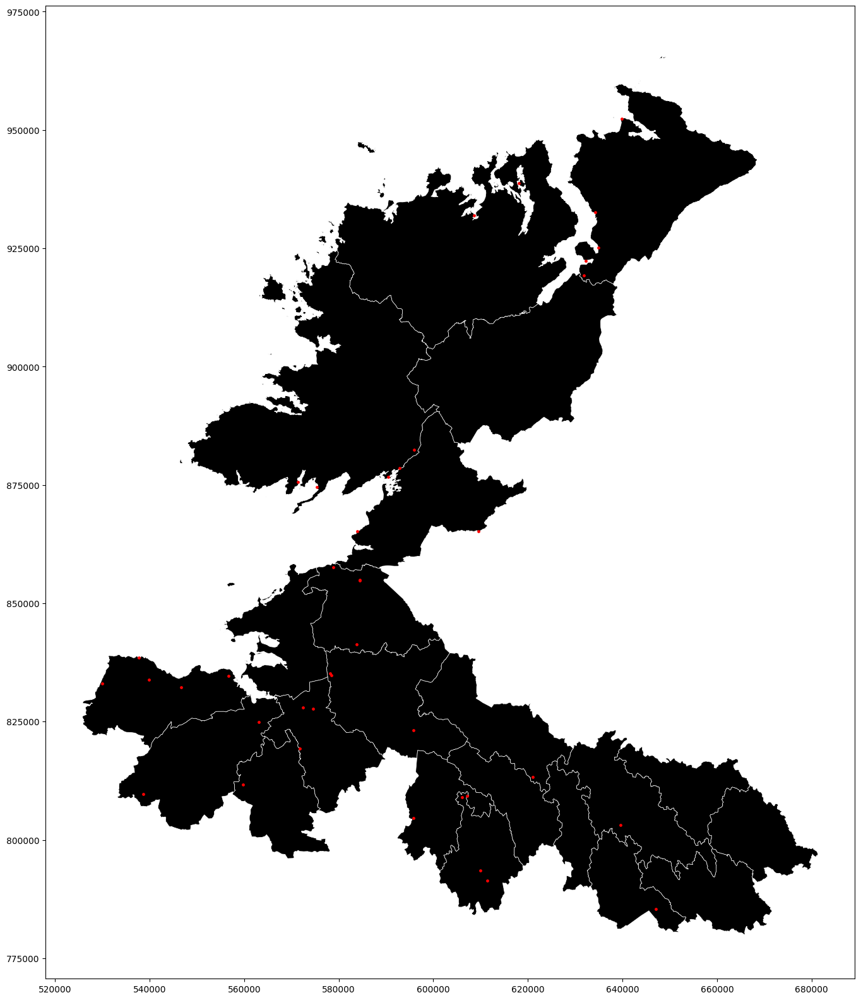

In [ ]:
# Plot the tower houses  on a map of the North West territories
# Label each tower house with its name
# Add a legend
# Add a title

fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5, )    
tower_houses.plot(ax=ax, color='red', markersize=6, label='Tower Houses')
plt.show()

Number of intersections: 32
Number of objects: 40
Percentage of objects intersecting with a boundary: 80.00%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
292     Remains of rectangular building (int. dims. 9....
1044    A three-storey tower house constructed of roug...
1440    Fahan Castle (site of): Mentioned in a grant t...
1567    Situated on a small rocky island, c. 300m from...
1903    Carrickabraghy Castle: Probably 16th century i...
2026    Moross Castle: Built in 1532 (Silke 1974, 30),...
2351    Doe Castle is a National Monument (No. 319) in...
2426    Buncrana Castle, described in 1601 as a small ...
2624    Inch Castle: First mentioned in 1454, this tow...
2634    Burt Castle: The earliest known reference to t...
3291    Donegal Castle is a National Monument (No.174)...
3301    This ruined structure is situated near the edg...
3356    Cat Castle: 'Cat Castle' or 'Kits Castle' is u...
3392    McSwyne's Castle: Niall Mar McSwyne, the grand...
3410    Ballyboyl

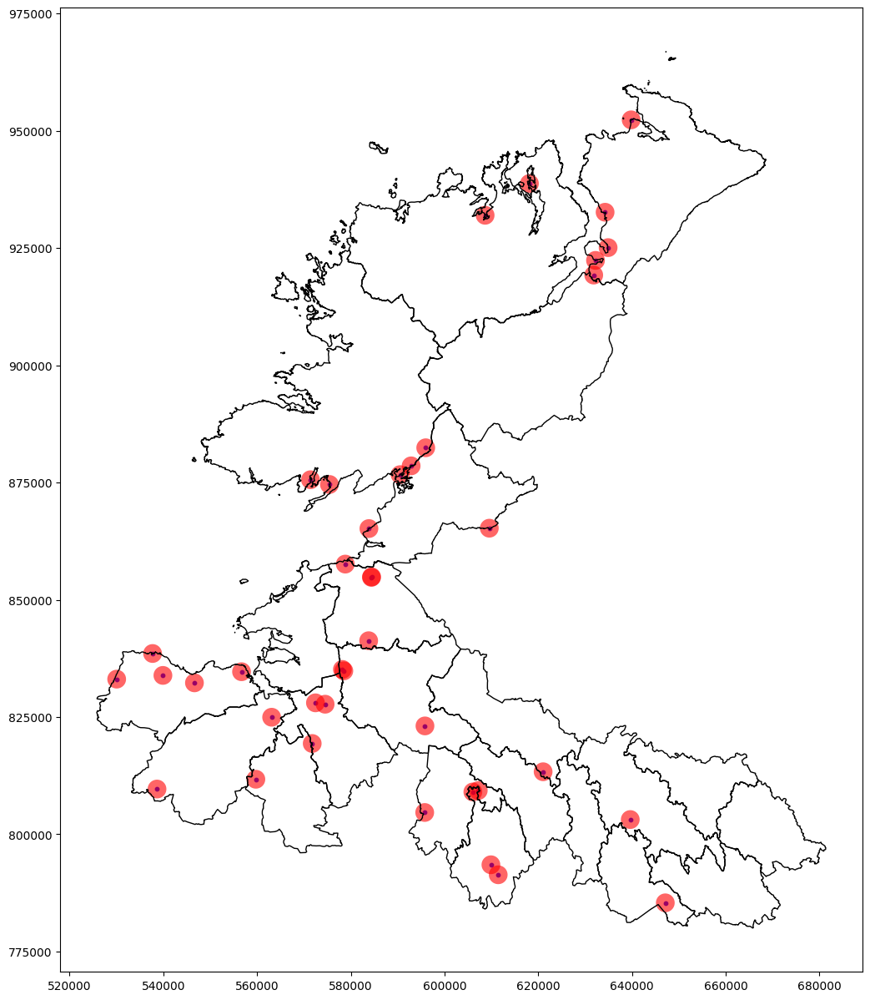

In [35]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = tower_houses # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
#parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
tower_houses.plot(ax=ax, color='blue', markersize=10)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

BOUNDARY CAIRNS

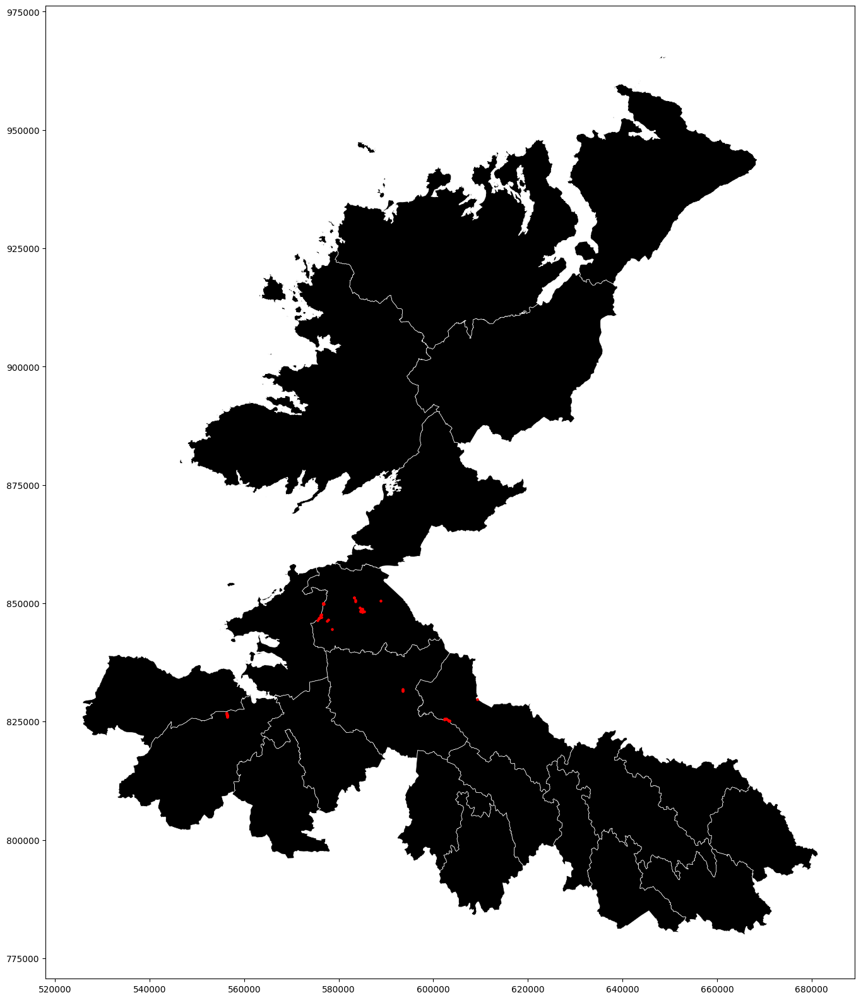

In [ ]:
# Plot the BOUNDARY CAIRNS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
boundary_cairns.plot(ax=ax, color='red', markersize=5)
plt.show()

Number of intersections: 43
Number of objects: 62
Percentage of objects intersecting with a boundary: 69.35%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
153     Not marked on OS 1836 or 1876 eds. Situated on...
155     Not marked on OS 1836 or 1876 eds. Situated on...
158     Not marked on OS 1836 or 1876 eds. Situated on...
183     Not marked on OS 1836 or 1876 eds. Situated on...
185     Not marked on OS 1836 or 1876 eds. Situated on...
191     Not marked on OS 1836 or 1876 eds. Situated on...
3950    Towards the top of a NE-facing slope which is ...
3951    At the summit of a ridge running N from Truskm...
3959    Marked only on the 1909 ed. of the OS 6-inch m...
3960    Marked only on the 1909 ed. of the OS 6-inch m...
3961    Marked only on the 1909 ed. of the OS 6-inch m...
3962    Marked only on the 1909 ed. of the OS 6-inch m...
3964    Marked only on the 1909 ed. of the OS 6-inch m...
3965    Marked only on the 1909 ed. of the OS 6-inch m...
3966    Marked on

NameError: name 'parishes_nw' is not defined

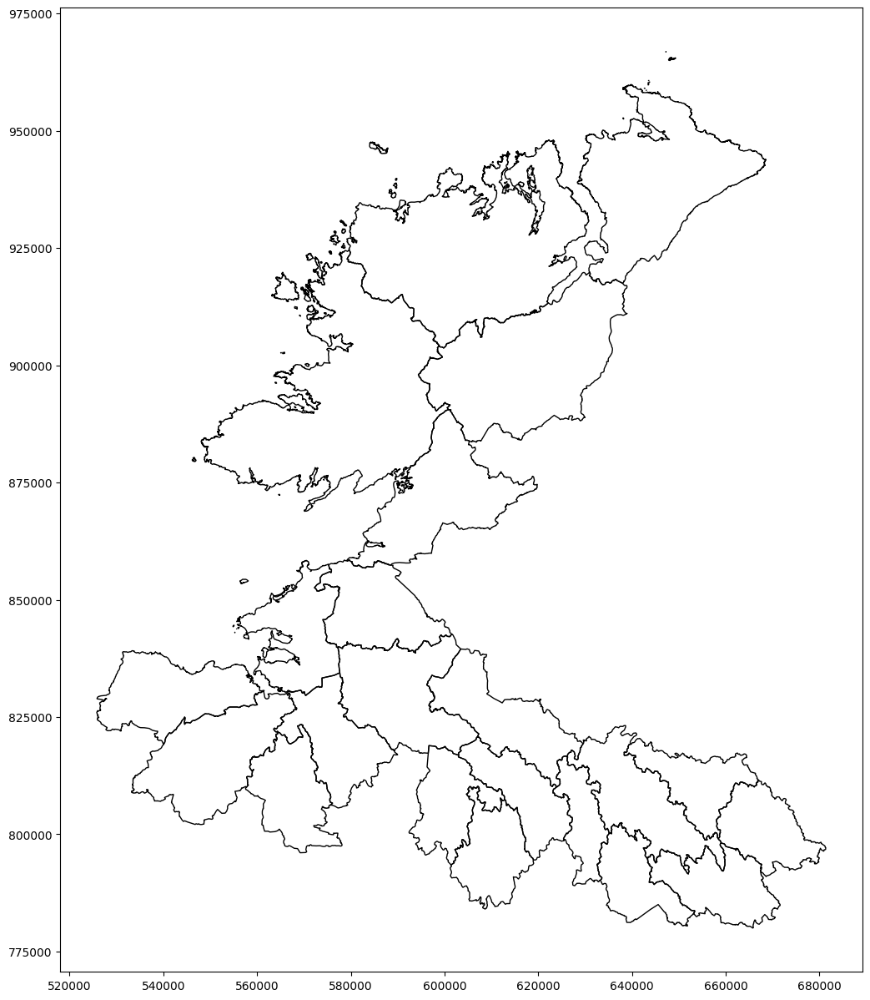

In [36]:
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = boundary_cairns # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the boundary to buffer



num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
tuatha_nw_1600_mod.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
boundary_cairns.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

CAIRNS 

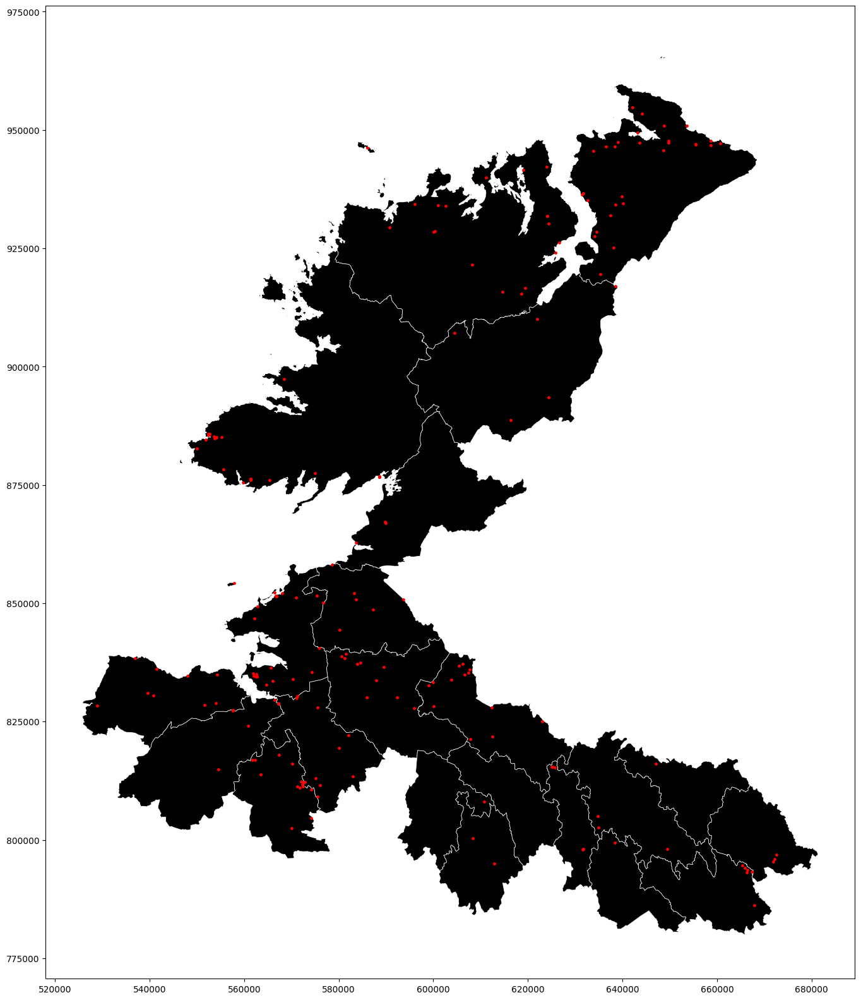

In [ ]:
# Plot the CAIRNS on a map of the North West territories
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='black', edgecolor='white', linewidth=0.5)    
cairns.plot(ax=ax, color='red', markersize=6)
plt.show()

BATTLEFIELDS

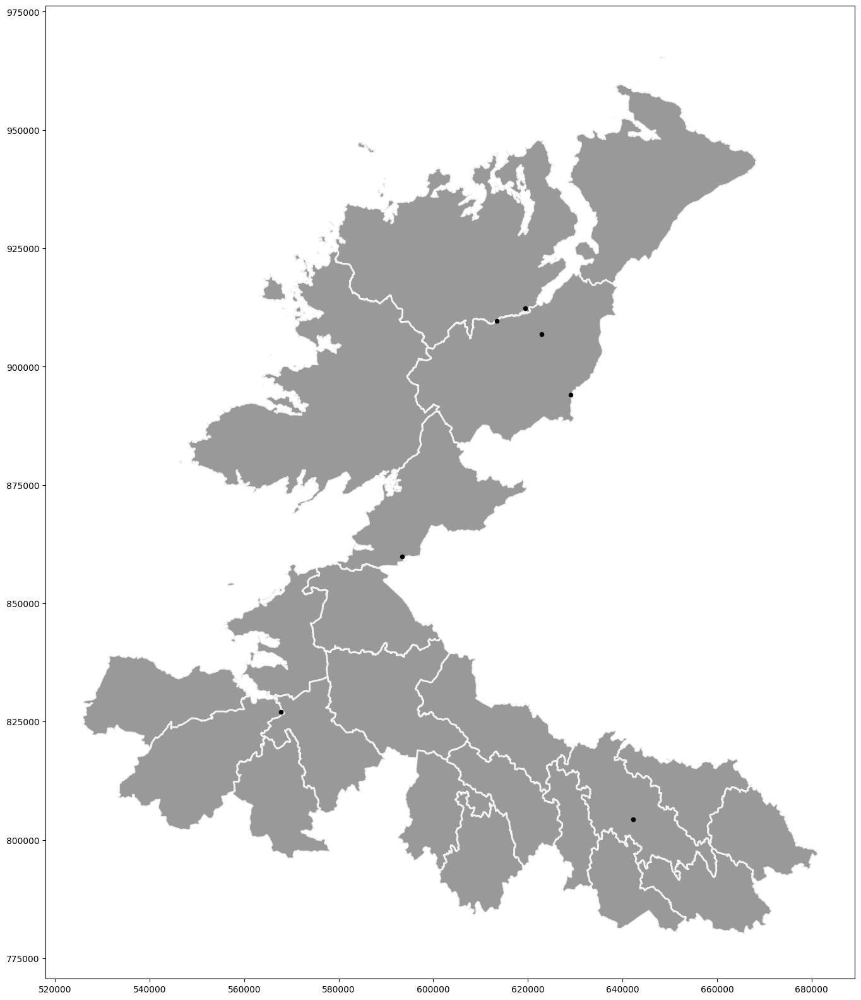

In [22]:
# Filter the dataframe for the 'Battlefield' category
battlefields = sites_nw_features[sites_nw_features['MONUMENT_T'] == 'Battlefield']

fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='white', linewidth=2, alpha=0.8)

# Plot the 'Battlefield' category
battlefields.plot(ax=ax, color='black', markersize=20, label='Battlefield')

plt.show()

# 71% of the battlefields intersect with a boundary

Number of intersections: 5
Number of objects: 7
Percentage of objects intersecting with a boundary: 71.43%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
9275    The Archaeological Survey of Ireland (ASI) is ...
9277    The Archaeological Survey of Ireland (ASI) is ...
9278    The Archaeological Survey of Ireland (ASI) is ...
9279    The Archaeological Survey of Ireland (ASI) is ...
9280    The Archaeological Survey of Ireland (ASI) is ...
Name: WEB_NOTES, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([9275, 9277, 9278, 9279, 9280], dtype='int64')


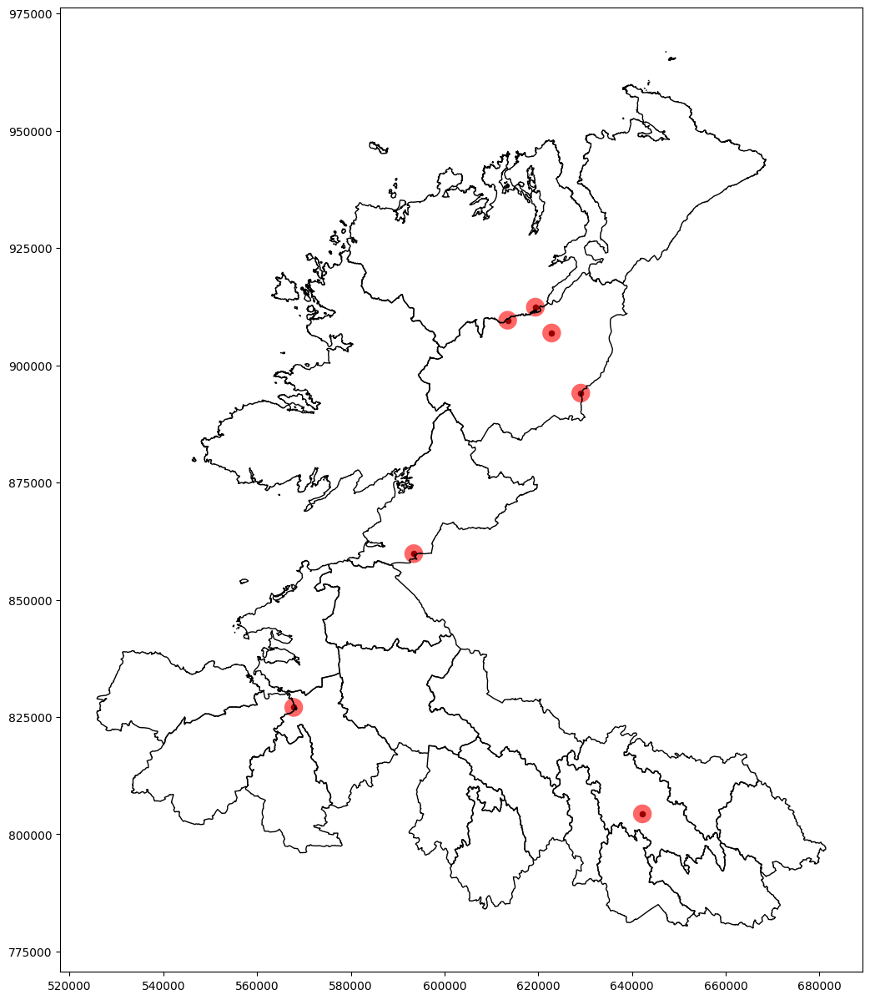

In [37]:
buffer_distance = 2000 # Adjust the buffer size as needed
archae_objects = battlefields # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod 

num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
#parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
battlefields.plot(ax=ax, color='black', markersize=20)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

In [ ]:
# get the WEB_NOTES entries for these Battlefields
battlefields['WEB_NOTES']



9274    The Archaeological Survey of Ireland (ASI) is ...
9275    The Archaeological Survey of Ireland (ASI) is ...
9276    The Archaeological Survey of Ireland (ASI) is ...
9277    The Archaeological Survey of Ireland (ASI) is ...
9278    The Archaeological Survey of Ireland (ASI) is ...
9279    The Archaeological Survey of Ireland (ASI) is ...
9280    The Archaeological Survey of Ireland (ASI) is ...
Name: WEB_NOTES, dtype: object

Number of intersections: 149
Number of objects: 202
Percentage of objects intersecting with a boundary: 73.76%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
12      Depicted as a circular enclosure on OS 1836 an...
128     Not marked on any OS ed. Identified in 1955 by...
146     Not marked on any OS ed. Situated in rough mou...
147     Marked on all OS eds. Situated on the S shore ...
150     Situated 10m SW of a wedge tomb (CV004-003----...
                              ...                        
9162    In a flat arable field by the north-east shore...
9176    The Archaeological Survey of Ireland (ASI) is ...
9187    In good pasture, on a steep NW-facing hillside...
9243    Among the sand dunes on Conor's Island. Remain...
9374    Located at the highest point on a plateau of r...
Name: WEB_NOTES, Length: 149, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([  12,  128,  146,  147,  150,  157,  173,  200,  215,  227,
       ...
 

NameError: name 'parishes_nw' is not defined

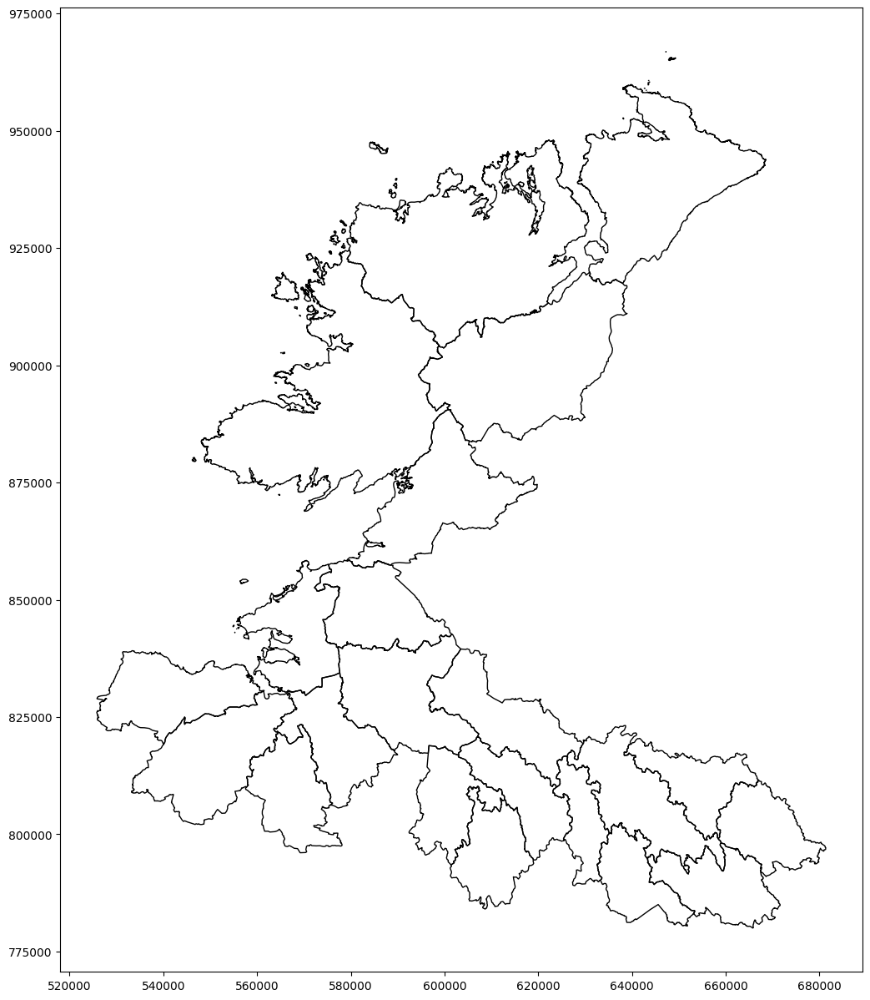

In [38]:
buffer_distance = 2000 # Adjust the buffer size as needed
archae_objects = cairns # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod 

num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
tuatha_nw_1600_mod.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)

# Plot the data points
cairns.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()

 THE SPATIAL DISTRIBUTION OF MONUMENTS RELATIVE TO BOUNDARIES.
 

Number of intersections: 238
Number of objects: 448
Percentage of objects intersecting with a boundary: 53.12%
WEB_NOTE for objects intersecting with a Tricha Cet boundary:
104     The Archaeological Survey of Ireland (ASI) is ...
317     Not marked on OS 1836 or 1876 eds. Sited on th...
326     Marked on all OS eds. Large irregular boulder ...
329     Not marked on OS 1836 ed. Situated 4.5m N of K...
348     Formerly sited on the W slope of a drumlin rid...
                              ...                        
9261    This stone stands among the sand dunes at Bund...
9270    On a slight WSW-facing slope in pasture. Low, ...
9310    In rough upland pasture, in the Ox Mountains, ...
9314    This standing stone is located close to the N ...
9463    In Gannew and Curreen townland, situated on a ...
Name: WEB_NOTES, Length: 238, dtype: object
Index number for objects intersecting with a Tricha Cet boundary:
Index([ 104,  317,  326,  329,  348,  349,  402,  434,  644,  722,
       ...
 

NameError: name 'parishes_nw' is not defined

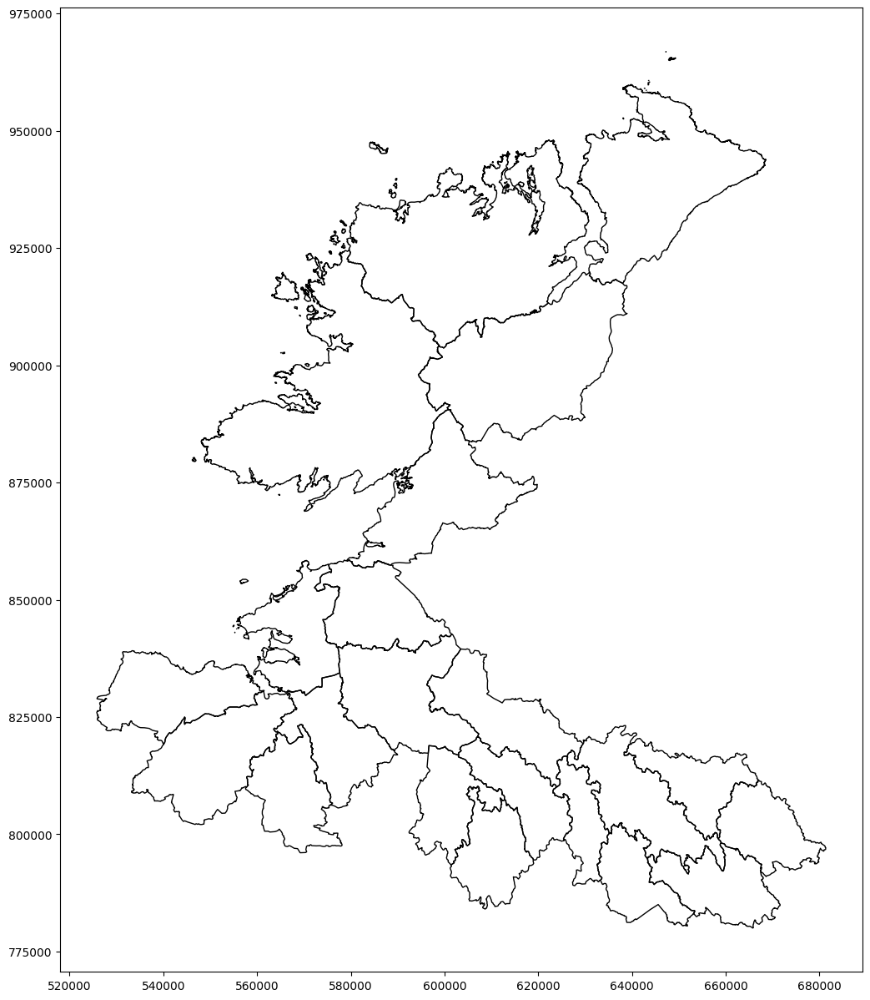

In [40]:
# Create a buffer around each Archaeological Object
buffer_distance = 2000  # Adjust the buffer size as needed
archae_objects = standing_stones # Choose the monument class to buffer
territory_boundary = tuatha_nw_1600_mod # Choose the territory boundary
#parish_boundary = parishes_nw # Choose the parish boundary



def buffer_object_intersection(archae_objects, buffer_distance, territory_boundary):
    
    # Create a buffer around each Archaeological Object
    monument_buffer = archae_objects.geometry.buffer(buffer_distance)  # Adjust the buffer size as needed

    # Get the boundary of the polygon
    boundary = territory_boundary.boundary.unary_union
    #parish_boundary = parish_boundary.boundary.unary_union

    # Check if each buffer intersects with the boundary
    intersections = monument_buffer.apply(lambda x: x.intersects(boundary))
    #parish_intersections = monument_buffer.apply(lambda x: x.intersects(parish_boundary))

    # Count the number of intersections
    num_intersections = intersections.sum()
    #num_parish_intersections = parish_intersections.sum()

    print(f"Number of intersections: {num_intersections}")
    print(f"Number of objects: {len(archae_objects)}")
    #print(f"Number of objects intersecting with a parish boundary: {num_parish_intersections}")
    print(f"Percentage of objects intersecting with a boundary: {num_intersections / len(archae_objects) * 100:.2f}%")
    #print(f"Percentage of objects intersecting with a parish boundary: {num_parish_intersections / len(archae_objects) * 100:.2f}%")

    # Print the WEB_NOTEs & index number for each object that intersects with the boundary
    print("WEB_NOTE for objects intersecting with a Tricha Cet boundary:")
    print(archae_objects[intersections]['WEB_NOTES'])
    print("Index number for objects intersecting with a Tricha Cet boundary:")
    print(archae_objects[intersections].index)

    # Print the index number for each object that intersects with the parish boundary
    #print("Index number for objects intersecting with a parish boundary:")
    #print(archae_objects[parish_intersections].index)



    return num_intersections, monument_buffer

num_intersections, monument_buffer = buffer_object_intersection(archae_objects, buffer_distance, territory_boundary)


fig, ax = plt.subplots(figsize=(15, 15))

# Plot the original boundary
territory_boundary.boundary.plot(ax=ax, color='black', linewidth=1)
parishes_nw.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, alpha=0.5)


# Plot the tower houses
standing_stones.plot(ax=ax, color='blue', markersize=4)

# Plot the buffer around the boundary
monument_buffer.plot(ax=ax, color='red', linewidth=1, alpha=0.6)

plt.show()



FURTHER INVESTIGATION/FEATURE Creation FROM DATA

In [ ]:
# Collect the percentage for each class of how many intersect with a boundary at 1000 metres


def buffer_object_intersection(archae_objects, buffer_distance, tuatha_nw_1600_mod):
    monument_buffer = archae_objects.geometry.buffer(buffer_distance)
    boundary = tuatha_nw_1600_mod.boundary.unary_union
    intersections = monument_buffer.apply(lambda x: x.intersects(boundary))
    num_intersections = intersections.sum()
    percentage = num_intersections / len(archae_objects) * 100
    return percentage

buffer_distance = 1000  # Adjust the buffer size as needed
monument_classes = sites_nw_clean['MONUMENT_T'].unique()

percentage_list = []
for monument_class in monument_classes:
    class_objects = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == monument_class]
    percentage = buffer_object_intersection(class_objects, buffer_distance, tuatha_nw_1600_mod)
    percentage_list.append(percentage)


print(percentage_list)

[51.89393939393939, 49.2063492063492, 28.957334006564, 44.37299035369775, 47.05882352941176, 32.142857142857146, 21.50537634408602, 28.859060402684566, 28.861154446177846, 34.32835820895522, 45.54140127388535, 28.72996300863132, 56.14035087719298, 31.52542372881356, 39.81481481481482, 25.694444444444443, 20.0, 38.46153846153847, 24.025974025974026, 36.93693693693694, 30.120481927710845, 48.484848484848484, 60.0, 60.0, 26.08695652173913, 45.0, 30.0, 21.21212121212121, 60.0, 34.61538461538461, 0.0, 43.333333333333336, 33.33333333333333, 33.33333333333333, 50.0, 41.66666666666667, 50.0, 64.28571428571429, 81.81818181818183, 47.61904761904761, 60.0, 0.0, 100.0, 47.368421052631575, 100.0, 66.66666666666666, 15.384615384615385, 50.0, 80.0, 50.0, 14.285714285714285, 50.0, 100.0, 60.86956521739131, 40.0, 50.0, 92.85714285714286, 95.91836734693877, 35.78947368421053, 33.33333333333333, 100.0, 50.0, 0.0, 27.77777777777778, 100.0, 37.5, 0.0, 0.0, 12.5, 0.0, 50.0, 24.489795918367346, 80.0, 50.0, 2

In [ ]:
sites_nw_clean['Boundary_Intersection_Percentage'] = pd.Series(percentage_list)

# Save the percentage list as a Geodataframe series.
sites_nw_clean.to_file("/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_features.shp")




/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_16284/3044811750.py:4: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  sites_nw_clean.to_file("/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_features.shp")


In [ ]:
sites_nw_clean.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry', 'Boundary_Intersection_Percentage'],
      dtype='object')

In [ ]:
# Obtain Booleans on whether an object intersects or not

def buffer_object_intersection(archae_objects, buffer_distance, tuatha_nw_1600_mod):
    monument_buffer = archae_objects.geometry.buffer(buffer_distance)
    boundary = tuatha_nw_1600_mod.boundary.unary_union
    intersections = monument_buffer.apply(lambda x: x.intersects(boundary))
    return intersections

buffer_distance = 1000  # Adjust the buffer size as needed
monument_classes = sites_nw_clean['MONUMENT_T'].unique()

intersection_list = []
for monument_class in monument_classes:
    class_objects = sites_nw_clean[sites_nw_clean['MONUMENT_T'] == monument_class]
    intersections = buffer_object_intersection(class_objects, buffer_distance, tuatha_nw_1600_mod)
    intersection_list.extend(intersections)

sites_nw_clean['Intersection'] = intersection_list


In [ ]:
sites_nw_clean.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'geometry', 'Boundary_Intersection_Percentage',
       'Intersection'],
      dtype='object')

In [ ]:
# Save the percentage list as a Geodataframe series.
sites_nw_clean.to_file("/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_features.shp")

/var/folders/lk/44yhnrk92p95sjc8gdd7165h0000gn/T/ipykernel_16284/3028776435.py:2: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  sites_nw_clean.to_file("/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_features.shp")


In [ ]:
sites_nw_clean.head

<bound method NDFrame.head of         OID_  OBJECTID ENTITY_ID CLASS_CODE           SMRS   COUNTY  \
0       2325      2325   LE00212       BOCA  LE004-021----  LEITRIM   
1       5325      5325   LE00213       BOCA  LE004-022----  LEITRIM   
2       5326      5326   LE00214       BOCA  LE004-023----  LEITRIM   
3       7588      7588   LE00215       BOCA  LE004-024----  LEITRIM   
4      19549     19549   CV01168       BAWN  CV025-098002-    CAVAN   
...      ...       ...       ...        ...            ...      ...   
9480  162057    162057   SL07570       RATH  SL039-169----    SLIGO   
9481  162060    162060   SL07572       RATH  SL019-264001-    SLIGO   
9482  162061    162061   SL07573       SOUT  SL019-264002-    SLIGO   
9483  162073    162073   SL07578       RATH  SL034-266----    SLIGO   
9484  162383    162383   LE02706       COEN  LE035-046----  LEITRIM   

                                               TOWNLAND  COUNTY_ID  ZONE_ID  \
0                                    C

NameError: name 'tower_houses_buffer' is not defined

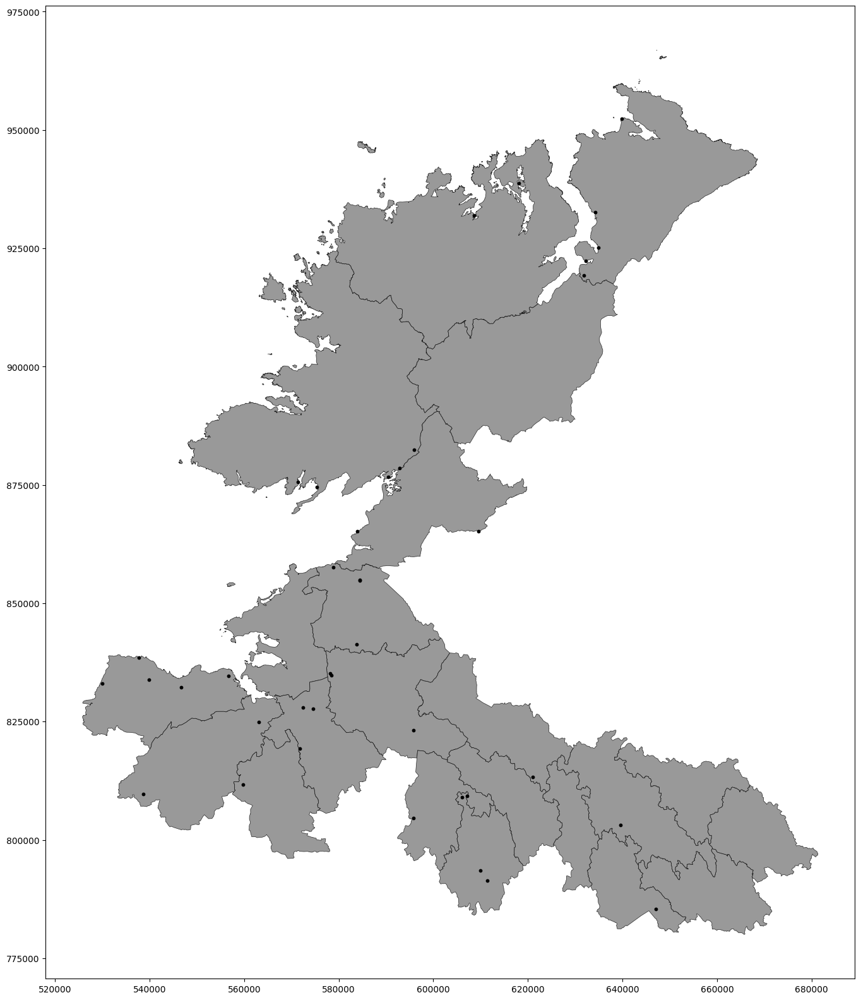

In [ ]:
fig, ax = plt.subplots(figsize=(20,20))
tuatha_nw_1600_mod.plot(ax=ax, color='grey', edgecolor='black', linewidth=0.5, alpha=0.8 )
# rivers.plot(ax=ax, color='blue', markersize=1, alpha=0.8)
sites_nw_features.plot(ax=ax, color='black', markersize=10, label='Tower Houses')
tower_houses_buffer.plot(ax=ax, color='white', alpha=0.5)
plt.show()

18


FEATURE ENGINEERING -- MONUMENTS 

Categorical features based on physical characteristics, location data, predicted age.





In [64]:
# Load the sites nw features file
sites_nw_features = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_features.shp')

sites_nw_features.columns
 

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'geometry'],
      dtype='object')

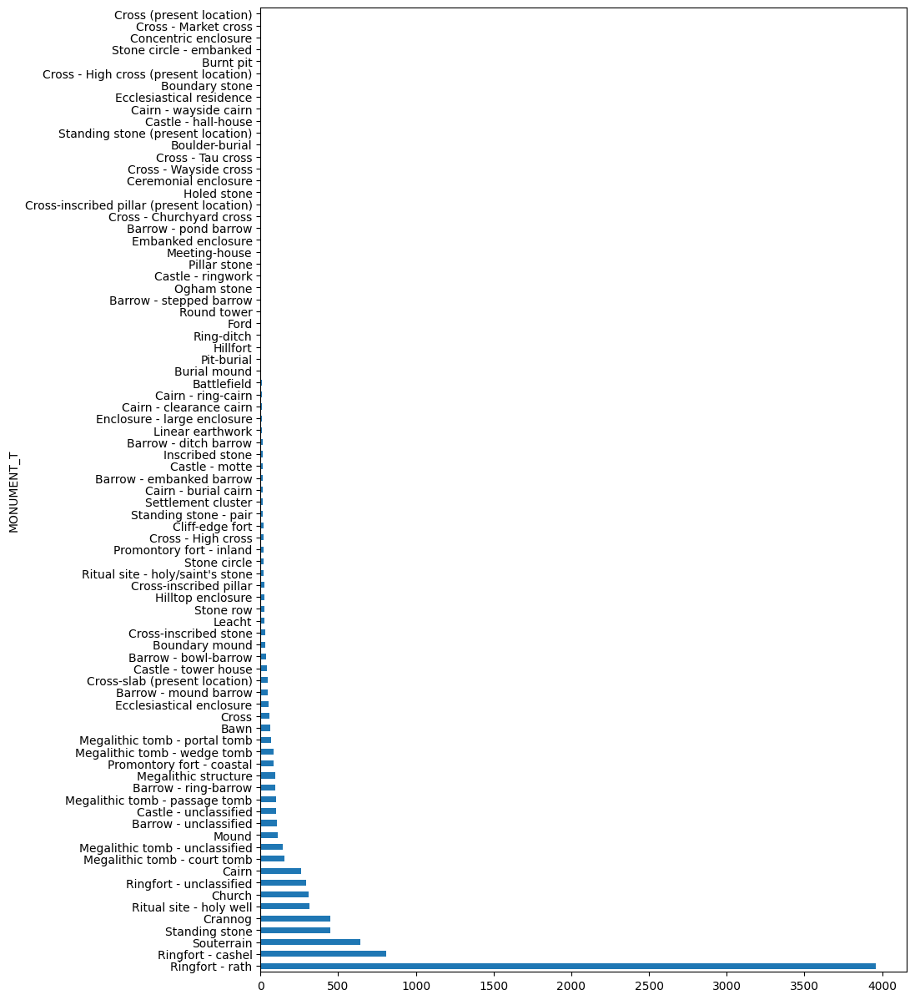

In [65]:
sites_nw_features['MONUMENT_T'].value_counts().plot(kind='barh', figsize=(10,15))   
plt.show()


In [ ]:
mon_count = sites_nw_features.groupby("MONUMENT_T").MONUMENT_T.count()
print(mon_count)

with open('monument_count.txt', 'w') as f:
    f.write(mon_count.to_string())



MONUMENT_T
Barrow - bowl-barrow                 37
Barrow - ditch barrow                12
Barrow - embanked barrow             14
Barrow - mound barrow                49
Barrow - pond barrow                  4
                                     ..
Standing stone (present location)     2
Standing stone - pair                15
Stone circle                         20
Stone circle - embanked               2
Stone row                            26
Name: MONUMENT_T, Length: 81, dtype: int64


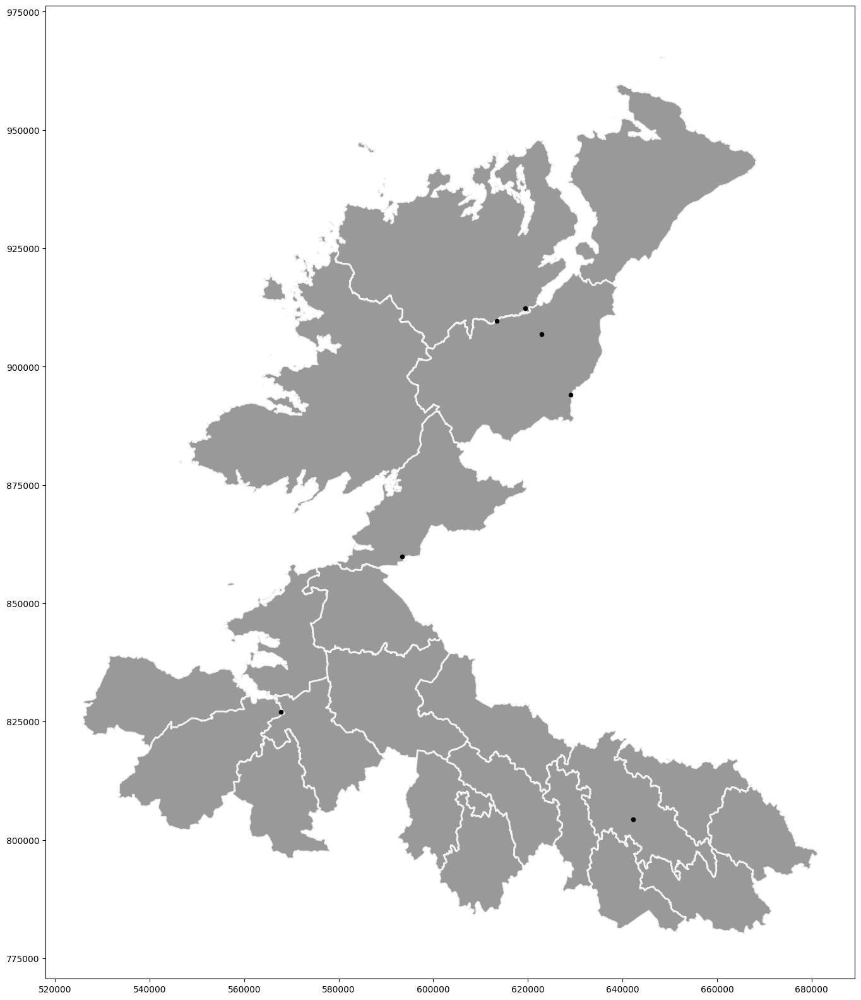

In [66]:
# Remove the following classes from the sites_nw_features file
# Meeting-house, Cross - Market cross - They are post 1600

sites_nw_features = sites_nw_features[sites_nw_features.MONUMENT_T != 'Meeting-house']
sites_nw_features = sites_nw_features[sites_nw_features.MONUMENT_T != 'Cross - Market cross']


In [68]:
# List monument types
monument_types = sites_nw_features['MONUMENT_T'].unique()
monument_types




array(['Cairn', 'Bawn', 'Ringfort - rath', 'Church',
       'Castle - unclassified', 'Standing stone', 'Megalithic structure',
       'Crannog', 'Souterrain', 'Megalithic tomb - portal tomb',
       'Ritual site - holy well', 'Ringfort - cashel', 'Cross',
       'Ringfort - unclassified', 'Barrow - unclassified',
       'Megalithic tomb - unclassified', 'Ring-ditch', 'Stone row',
       'Megalithic tomb - court tomb', 'Mound',
       'Megalithic tomb - wedge tomb', 'Boundary mound', 'Ford',
       'Castle - tower house', 'Hilltop enclosure', 'Stone circle',
       'Promontory fort - inland', 'Megalithic tomb - passage tomb',
       'Round tower', 'Ecclesiastical enclosure',
       'Ecclesiastical residence', 'Cross-inscribed stone',
       'Ceremonial enclosure', 'Enclosure - large enclosure',
       'Inscribed stone', 'Concentric enclosure', 'Settlement cluster',
       'Linear earthwork', "Ritual site - holy/saint's stone",
       'Ogham stone', 'Cross - Wayside cross',
       'Promo

In [71]:
# Create a column called Material and populate it with the material of the monument
# Define your dictionary
# Add more monument types as needed

material_dict = {
    'Cairn': 'Stone',
    'Bawn': 'Stone',  
    'Ringfort - rath': 'Earth', 
    'Church': 'Stone',
    'Castle - unclassified': 'Stone',
    'Standing stone': 'Stone',
    'Megalithic structure': 'Stone',
    'Crannog': 'Stone',
    'Souterrain': 'Stone',
    'Megalithic tomb - portal tomb'
    'Ritual site - holy well' : 'Stone',
    'Ringfort - cashel' : 'Stone',
    'Cross' : 'Stone',
    'Ringfort - unclassified' : 'Earth',
    'Barrow - unclassified' : 'Earth',
    'Megalithic tomb - unclassified' : 'Stone',  
    'Ring-ditch' : 'Earth',
    'Stone row' : 'Stone',
    'Megalithic tomb - court tomb' : 'Stone',
    'Mound' : 'Earth',
    'Megalithic tomb - wedge tomb' : 'Stone',
    'Boundary mound' : 'Earth',
    'Ford' : 'Earth',
    'Castle - tower house' : 'Stone',
    'Hilltop enclosure' : 'Earth',
    'Stone circle' : 'Stone',
    'Promontory fort - inland' : 'Earth',
    'Megalithic tomb - passage tomb' : 'Stone',
    'Round tower' : 'Stone',
    'Ecclesiastical enclosure' : 'Stone',
    'Ecclesiastical residence' : 'Stone',
    'Cross-inscribed stone' : 'Stone',
    'Ceremonial enclosure' : 'Earth',
    'Enclosure - large enclosure' : 'Earth',
    'Inscribed stone' : 'Stone',
    'Concentric enclosure' : 'Earth',
    'Settlement cluster' : 'Earth',
    'Linear earthwork' : 'Earth',
    "Ritual site - holy/saint's stone" : 'Stone',
    'Ogham stone' : 'Stone',
    'Cross - Wayside cross' : 'Stone',
    'Promontory fort - coastal' : 'Earth',
    'Cross - High cross' : 'Stone',
    'Cross - Churchyard cross' : 'Stone',
    'Holed stone' : 'Stone',
    'Castle - motte' : 'Stone',
    'Castle - ringwork' : 'Stone',
    'Burial mound' : 'Earth',
    'Cairn - burial cairn' : 'Earth',
    'Burnt pit' : 'Earth',
    'Standing stone (present location)' : 'Stone',
    'Cross-inscribed pillar' : 'Stone',
    'Pillar stone' : 'Stone',
    'Cross - Tau cross' : 'Stone',
    'Leacht' : 'Stone',
    'Cross-slab (present location)' : 'Stone',
    'Barrow - ring-barrow' : 'Earth',
    'Standing stone - pair' : 'Stone',
    'Cross-inscribed pillar (present location)' : 'Stone',
    'Pit-burial' : 'Earth',
    'Hillfort' : 'Earth',
    'Cliff-edge fort' : 'Earth',
    'Stone circle - embanked' : 'Stone',
    'Cairn - clearance cairn' : 'Stone',
    'Barrow - pond barrow' : 'Earth',
    'Cross - High cross (present location)' : 'Stone',
    'Cairn - ring-cairn' : 'Stone',
    'Cairn - wayside cairn' : 'Stone',
    'Boundary stone' : 'Stone',
    'Barrow - mound barrow' : 'Earth',
    'Barrow - stepped barrow' : 'Earth',
    'Castle - hall-house' : 'Stone',
    'Barrow - bowl-barrow' : 'Earth',
    'Barrow - embanked barrow' : 'Earth',
    'Embanked enclosure' : 'Earth',
    'Barrow - ditch barrow' : 'Earth',
    'Cross (present location)' : 'Stone',
    'Boulder-burial' : 'Stone',
    'Battlefield': 'Earth',

}

# Create the new column
sites_nw_features['Material'] = sites_nw_features['MONUMENT_T'].map(material_dict)



In [72]:
sites_nw_features.columns

Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'geometry', 'Material'],
      dtype='object')

In [73]:
sites_nw_features['Material']


0       Stone
1       Stone
2       Stone
3       Stone
4       Stone
        ...  
9480    Earth
9481    Earth
9482    Stone
9483    Earth
9484    Earth
Name: Material, Length: 9479, dtype: object

In [74]:
# Load soils map data
soils_nw = gpd.read_file('/Users/mensab/Documents/GISMapFiles/Files1600/soils_map_nw.shp')
# soils_nw.head()



In [56]:
soils_nw.head()



,BY_ID,ENGLISH,GAEILGE,LOGAINM_ID,CONTAE,COUNTY,PROVINCE,GUID,CENTROID_X,CENTROID_Y,...,ha,URL,UniqueID,DRAINAGE,TEXTURE,DEPTH,SHAPE_Leng,SHAPE_Area,SOC,geometry
0,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,9.696484,http://gis.teagasc.ie/soils/,2877,Poor,Peat,NaN,2895.714564,96964.847077,0.0,"POLYGON ((635766.844 809566.516, 635773.420 80..."
1,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,30.859582,http://gis.teagasc.ie/soils/,2887,Poor,Peat,NaN,8253.807654,308595.830317,0.0,"POLYGON ((634217.362 810308.775, 634285.658 81..."
2,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,9.705475,http://gis.teagasc.ie/soils/,2899,Poor,Peat,NaN,2737.026809,97054.747857,0.0,"POLYGON ((631261.950 810589.847, 631085.879 81..."
3,29008,TULLYHUNCO,Teallach Dhúnchadha,15,An Cabhán,CAVAN,Ulster,2ae19629-11c1-13a3-e055-000000000001,629128.31,802860.29,...,9.705475,http://gis.teagasc.ie/soils/,2899,Poor,Peat,NaN,2737.026809,97054.747857,0.0,"POLYGON ((630826.397 810700.688, 631085.879 81..."
4,29004,LOUGHTEE LOWER,Lucht Tí Íochtarach,13,An Cabhán,CAVAN,Ulster,2ae19629-11bd-13a3-e055-000000000001,634144.23,815372.62,...,10.334379,http://gis.teagasc.ie/soils/,2931,Poor,Peat,NaN,2053.385719,103343.786336,0.0,"MULTIPOLYGON (((639154.271 811760.516, 638999...."


In [75]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point

def get_soil_type(point):
    for idx, row in soils_nw.iterrows():
        if point.within(row.geometry):
            return row['Texture_Su']
    return None

# Apply the function to the 'geometry' column
sites_nw_features['SOILS'] = sites_nw_features['geometry'].apply(get_soil_type)





In [76]:
sites_nw_features.columns



Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'geometry', 'Material',
       'SOILS'],
      dtype='object')

In [79]:
sites_nw_features['SOILS'].nunique()


31

In [80]:
# Save the sites_nw_features file
sites_nw_features.to_file("/Users/mensab/Documents/GISMapFiles/Files1600/sites_nw_features.shp")



In [63]:
joined.columns


Index(['OID_', 'OBJECTID', 'ENTITY_ID', 'CLASS_CODE', 'SMRS', 'COUNTY_left',
       'TOWNLAND', 'COUNTY_ID', 'ZONE_ID', 'ITM_E', 'ITM_N', 'LATITUDE',
       'LONGITUDE', 'MONUMENT_T', 'FIRST_EDIT', 'LATEST_EDI', 'WEBSITE_LI',
       'WEB_NOTES', 'Boundary_I', 'Intersecti', 'geometry', 'Material',
       'DRAINAGE_left', 'TEXTURE_left', 'index_right', 'BY_ID', 'ENGLISH',
       'GAEILGE', 'LOGAINM_ID', 'CONTAE', 'COUNTY_right', 'PROVINCE', 'GUID',
       'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID_1', 'Shape__Are',
       'Shape__Len', 'OBJECTID_2', 'Associatio', 'Associat_1', 'Associat_2',
       'Texture_Su', 'ha', 'URL', 'UniqueID', 'DRAINAGE_right',
       'TEXTURE_right', 'DEPTH', 'SHAPE_Leng', 'SHAPE_Area', 'SOC'],
      dtype='object')

In [ ]:
tuatha_nw_1600_mod.columns

Index(['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'AIREACHT', 'FEDERATION',
       'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID',
       'Shape__Are', 'Shape__Len', 'geometry'],
      dtype='object')

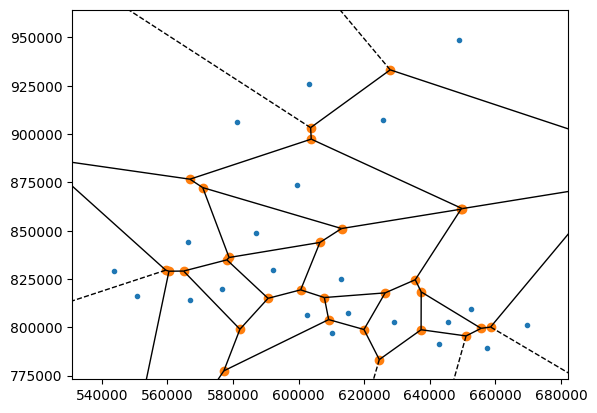

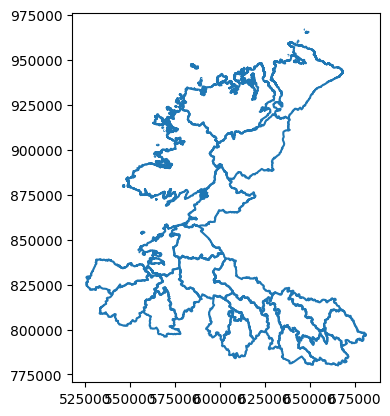

In [ ]:
# Plot a Voronoi tessellation map generated from the centroids of the polygon map


from scipy.spatial import Voronoi, voronoi_plot_2d
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np


# Create a list of tuples where each tuple contains the x and y coordinates of a centroid
points = list(zip(tuatha_nw_1600_mod['CENTROID_X'], tuatha_nw_1600_mod['CENTROID_Y']))

# Create a Voronoi tessellation based on the centroids
vor = Voronoi(points)

# Plot the Voronoi tessellation
voronoi_plot_2d(vor)

# Overlay the original polygons on the Voronoi tessellation
tuatha_nw_1600_mod.boundary.plot()

plt.show()



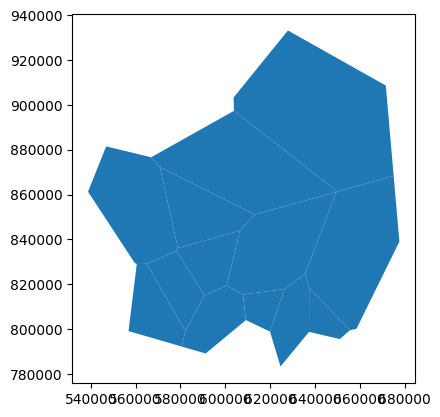

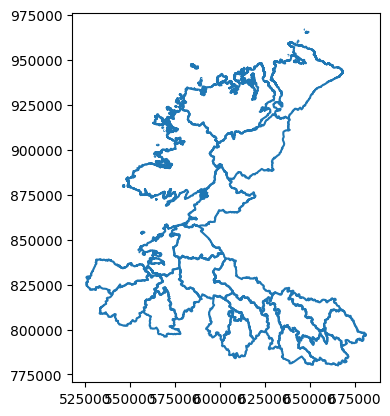

In [ ]:
from shapely.geometry import Polygon, Point

# Create a list of tuples where each tuple contains the x and y coordinates of a centroid
points = list(zip(tuatha_nw_1600_mod['CENTROID_X'], tuatha_nw_1600_mod['CENTROID_Y']))

# Create a Voronoi tessellation based on the centroids
vor = Voronoi(points)

# Create a polygon from the boundary of the original map
boundary_poly = tuatha_nw_1600_mod.unary_union.convex_hull

# Create an empty GeoDataFrame to store the Voronoi polygons
voronoi_gdf = gpd.GeoDataFrame(columns=['geometry'])

# For each Voronoi region
for region in vor.regions:
    if not -1 in region and len(region) > 0:
        # Create a polygon for the region and intersect it with the boundary
        region_poly = Polygon([vor.vertices[i] for i in region])
        intersection = boundary_poly.intersection(region_poly)
        
        # Add the intersection to the GeoDataFrame
        new_row = gpd.GeoDataFrame({'geometry': [intersection]}, crs=voronoi_gdf.crs)
        voronoi_gdf = pd.concat([voronoi_gdf, new_row], ignore_index=True)

# Plot the Voronoi polygons
voronoi_gdf.plot()

# Overlay the original polygons
tuatha_nw_1600_mod.boundary.plot()

plt.show()

Spatial Point Analysis. 
Analyse the point pattern of the data. This will help us understand the spatial distribution of the data. We can use the following methods to analyse the point pattern of the data:
- Ripley's K function
- Moran's I
- Geary's C
- L function    


In [ ]:
from pointpats import (
    distance_statistics,
    QStatistic,
    random,
    PointPattern,
)

In [ ]:
# Convert the x.y coords to an array.
# Extract x and y coordinates from the 'geometry' column
raths_coords = [(point.x, point.y) for point in raths.geometry]

# Create a PointPattern object
raths_points = PointPattern(raths_coords)

Point Pattern
3961 points
Bounding rectangle [(19550,19550), (162073,162073)]
Area of window: 20312805529.0
Intensity estimate for window: 1.9500014384251331e-07
       x      y   mark_0 mark_1         mark_2 mark_3  \
5  19550  19550  CV01169   RATH  CV025-099----  CAVAN   
6  19559  19559  CV01155   RATH  CV025-087----  CAVAN   
7  19560  19560  CV01156   RATH  CV025-088----  CAVAN   
8  19563  19563  CV01159   RATH  CV025-090----  CAVAN   
9  19564  19564  CV01160   RATH  CV025-092----  CAVAN   

                    mark_4  mark_5   mark_6  mark_7  mark_8     mark_9  \
5  NEWTOWN (Clanmahon By.)       3  R168132  636873  799493  53.943449   
6          LISMORE DEMESNE       3  R168161  637053  800272  53.950436   
7          LISMORE DEMESNE       3  R168156  637103  800132  53.949174   
8              LISNAMANDRA       3  R170277  637883  801992  53.965831   
9            LOUGHACONNICK       3  R170259  640162  801642  53.962514   

    mark_10          mark_11 mark_12   mark_13  \


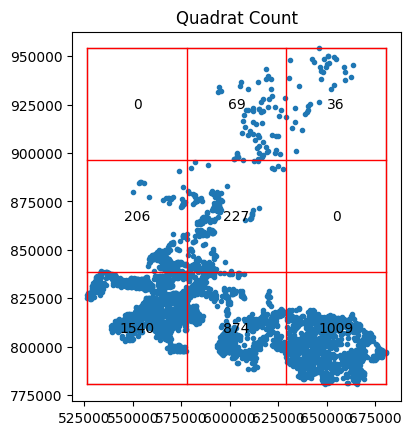

In [ ]:
# Apply QStatistic to the PointPattern object
raths_points = PointPattern(raths)
raths_points.summary()

qstat.plot()
plt.show()

# Create a PointPattern object
# Plot the QStatistic




pointpats.pointpattern.PointPattern

In [ ]:
from pointpats import PointPattern
from pysal.explore.pointpats import K, PoissonPointProcess, Window
import numpy as np
import matplotlib.pyplot as plt

# Define the study area as a rectangle
min_x, min_y, max_x, max_y = raths.geometry.total_bounds
window = Window([[(min_x, min_y), (min_x, max_y), (max_x, max_y), (max_x, min_y), (min_x, min_y)]])

# Generate a Poisson Point Process for comparison
ppp = PoissonPointProcess(window, len(raths_points.points), 100, asPP=True)

# Compute the K-function
k_real = K(raths_points.points)
k_rand = K(ppp.realizations[0].points)

# Compute the distances for the K-function
distances = np.linspace(0, max_x - min_x, 100)

# Compute the K-function values for the real and random data
k_real_values = [k_real.function(d) for d in distances]
k_rand_values = [k_rand.function(d) for d in distances]

# Plot the K-function
plt.figure()
plt.plot(distances, k_real_values, label='Real')
plt.plot(distances, k_rand_values, label='Random')
plt.legend()
plt.title('K-function')
plt.show()

/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/spaghetti/network.py:40: FutureWarning: The next major release of pysal/spaghetti (2.0.0) will drop support for all ``libpysal.cg`` geometries. This change is a first step in refactoring ``spaghetti`` that is expected to result in dramatically reduced runtimes for network instantiation and operations. Users currently requiring network and point pattern input as ``libpysal.cg`` geometries should prepare for this simply by converting to ``shapely`` geometries.
  warnings.warn(dep_msg, FutureWarning, stacklevel=1)


ImportError: cannot import name 'K' from 'pysal.explore.pointpats' (/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/pysal/explore/pointpats/__init__.py)

In [ ]:
from pointpats import K, G, PoissonPointProcess, Window
import matplotlib.pyplot as plt

# Define the study area as a rectangle
min_x, min_y, max_x, max_y = raths.geometry.total_bounds
window = Window([[(min_x, min_y), (min_x, max_y), (max_x, max_y), (max_x, min_y), (min_x, min_y)]])

# Generate a Poisson Point Process for comparison
ppp = PoissonPointProcess(window, len(raths_points.points), 100, asPP=True)

# Compute the K-function
k_real = K(raths_points, window=window)
k_rand = K(ppp, window=window)

# Compute the G-function
g_real = G(raths_points, window=window)
g_rand = G(ppp, window=window)

# Plot the K-function
plt.figure()
plt.plot(k_real[0], k_real[1], label='Real')
plt.plot(k_rand[0], k_rand[1], label='Random')
plt.legend()
plt.title('K-function')
plt.show()

# Plot the G-function
plt.figure()
plt.plot(g_real[0], g_real[1], label='Real')
plt.plot(g_rand[0], g_rand[1], label='Random')
plt.legend()
plt.title('G-function')
plt.show()

ImportError: cannot import name 'K' from 'pointpats' (/Users/mensab/Documents/GitHub/Artefact/artefactenv/lib/python3.11/site-packages/pointpats/__init__.py)

In [ ]:
#




18


In [ ]:
raths['cluster']

KeyError: 'cluster'

NameError: name 'clusters' is not defined

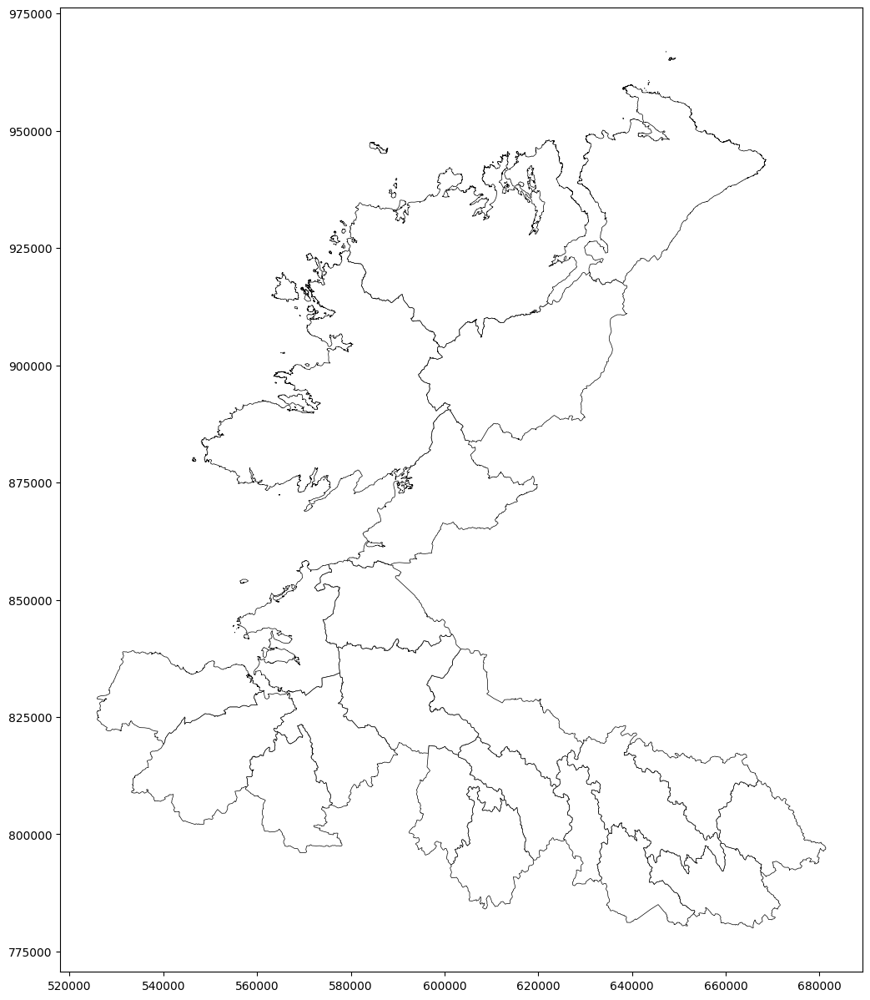

In [ ]:
# Setup figure and axis
f, ax = plt.subplots(1, figsize=(15, 15))
tuatha_nw_1600_mod.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5, zorder=1)


# Subset points that are not part of any cluster (noise)
noise = raths.loc[clusters == -1, ["x", "y"]]

# Plot noise in grey
ax.scatter(noise["x"], noise["y"], c="grey", s=5, linewidth=0, zorder=2)

# Plot all points that are not noise in red
# NOTE this is done through some fancy indexing, where
#      we take the index of all points (db) and substract from
#      it the index of those that are noise
ax.scatter(
    raths.loc[raths.index.difference(noise.index), "x"],
    raths.loc[raths.index.difference(noise.index), "y"],
    c="red",
    linewidth=0,
)

# Remove axes
ax.set_axis_off()
# Display the figure
plt.show()

In [ ]:
sites_nw_clean.info

<bound method DataFrame.info of         OID_  OBJECTID ENTITY_ID CLASS_CODE           SMRS   COUNTY  \
0       2325      2325   LE00212       BOCA  LE004-021----  LEITRIM   
1       5325      5325   LE00213       BOCA  LE004-022----  LEITRIM   
2       5326      5326   LE00214       BOCA  LE004-023----  LEITRIM   
3       7588      7588   LE00215       BOCA  LE004-024----  LEITRIM   
4      19549     19549   CV01168       BAWN  CV025-098002-    CAVAN   
...      ...       ...       ...        ...            ...      ...   
9480  162057    162057   SL07570       RATH  SL039-169----    SLIGO   
9481  162060    162060   SL07572       RATH  SL019-264001-    SLIGO   
9482  162061    162061   SL07573       SOUT  SL019-264002-    SLIGO   
9483  162073    162073   SL07578       RATH  SL034-266----    SLIGO   
9484  162383    162383   LE02706       COEN  LE035-046----  LEITRIM   

                                               TOWNLAND  COUNTY_ID  ZONE_ID  \
0                                   

0       Marked only on the 1910 ed. of the OS 6-inch m...
1       Marked only on the 1910 ed. of the OS 6-inch m...
2       Marked only on the 1910 ed. of the OS 6-inch m...
3       Marked only on the 1910 ed. of the OS 6-inch m...
4       Davies (1948a, 115) recorded the site of a pla...
                              ...                        
9480    In pasture, on the level top of a low hill/dru...
9481    In good coastal grassland, 1km S of Ballysadar...
9482    In a rath (SL019-264001-), close to the NE arc...
9483    In rough, rush-grown upland pasture, located o...
9484    Reported by Jean-Charles Caillere; visible on ...
Name: WEB_NOTES, Length: 9485, dtype: object

bank 4731
area 4719
int 3927
circular 3906
diam 3599
wth 3577
5m 2904
circular area 2825
enclosed 2644
earthen 2627
pasture 2615
raised 2475
fosse 2452
situated 2363
stone 2224
earthen bank 2208
slope 2132
facing 2094
se 2059
ne 2015
os 1975
sw 1969
low 1956
nw 1936
area int 1857


In [ ]:
# Sample WEB_NOTES entries that have the word diam or wth in them

# Create a list of words/phrases to search for
search_words = ['diam' 'area int']

# Create a list of indices where the search words/phrases are found
search_indices = []
for i, note in enumerate(sites_nw_clean['WEB_NOTES']):
    if any(word in note for word in search_words):
        search_indices.append(i)

# Display sample entries based on the found indices
sample_entries = sites_nw_clean.loc[search_indices, 'WEB_NOTES']
print(sample_entries)

Series([], Name: WEB_NOTES, dtype: object)


In [ ]:
sample_entries.iloc[9477]

IndexError: single positional indexer is out-of-bounds

IndexError: single positional indexer is out-of-bounds

In [ ]:
# Use regex to extract both "diam" and "wth" and their respective diameters

pattern_diam = r'diam(?:eter)?\s*([\d.]+)'
pattern_wth = r'wth(?:\s*is)?\s*([\d.]+)'

sites_nw_clean['Diameter_diam'] = sites_nw_clean['WEB_NOTES'].str.extract(pattern_diam, flags=re.IGNORECASE)
sites_nw_clean['Diameter_wth'] = sites_nw_clean['WEB_NOTES'].str.extract(pattern_wth, flags=re.IGNORECASE)




In [ ]:
#  Convert the 'Diameter_diam' and 'Diameter_wth' columns to numeric (float) type

sites_nw_clean['Diameter_diam'] = pd.to_numeric(sites_nw_clean['Diameter_diam'], errors='coerce')
sites_nw_clean['Diameter_wth'] = pd.to_numeric(sites_nw_clean['Diameter_wth'], errors='coerce')



In [ ]:
# Sum the diameter values from "diam" and "wth" and create a new 'Diameter' column
sites_nw_clean['Diameter'] = sites_nw_clean['Diameter_diam'] + sites_nw_clean['Diameter_wth']


# Replace NaN values in 'Diameter' with 0
sites_nw_clean['Diameter'].fillna(0, inplace=True)

In [ ]:
# Drop the intermediate columns
sites_nw_clean.drop(columns=['Diameter_diam', 'Diameter_wth'], inplace=True)


In [ ]:
# Display the result
sites_nw_clean['Diameter']

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
9480    0.0
9481    0.0
9482    0.0
9483    0.0
9484    0.0
Name: Diameter, Length: 9485, dtype: float64

In [ ]:
# Create a function to find words in a text, or import those ive alreafy written


def find_words(text):
    words_to_find = ['univallate', 'bivallate','trivallate','bi-vallate', 'tri-vallate', 'single ditch', 'double ditch', 'triple ditch', 'single bank', 'double bank', 'triple bank', 'single rampart', 'double rampart', 'triple rampart', 'triple enclosure']
    found_words = [word for word in words_to_find if word in text]
    return ', '.join(found_words)


# Apply the function to create a new column 'found_words'
sites_nw_clean['found_words'] = sites_nw_clean['WEB_NOTES'].apply(find_words)

In [ ]:
sites_nw_clean['found_words'].value_counts()

In [ ]:
# find row with 'trivallate' in 'found_words' column
trivallate = sites_nw_clean[sites_nw_clean['found_words'] == 'trivallate']
trivallate.head()

In [ ]:
pd.DataFrame(filtered_points_2['MONUMENT_T'].value_counts()).plot.bar(width=0.5, figsize=(15,6))
plt.show()